In [1]:
# Журнал 
LOG_COLS = ["field", "issue", "scope", "n_rows", "value_before", "action", "value_after", "rationale"]
cleaning_log = []

def add_log(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    cleaning_log.append(dict(zip(LOG_COLS, [field, issue, scope, n_rows, value_before, action, value_after, rationale])))


## 0. Зачитаем данные 

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

RAW_PATH = Path("..") / "data" / "raw" / "rent_v28.csv"
INTERIM_PATH = Path("..") / "data" / "interim" / "test.csv"

print(RAW_PATH.resolve(), "| файл найден:", RAW_PATH.exists())

df_naive = pd.read_csv(RAW_PATH, sep=";", encoding="cp1251", dtype={"id": "string"})

print(f"Размер: {df_naive.shape[0]} строк × {df_naive.shape[1]} столбцов")
df_naive.head(3)

C:\Users\6anna\PycharmProjects\Suhodolova_Anna_Lab2\data\raw\rent_v28.csv | файл найден: True
Размер: 12360 строк × 1 столбцов


,listing_id|publication_date|district|house_type|year_built|floors_total|floor|elevator|rooms|total_area|living_area|kitchen_area|ceiling_height|renovation|furniture|appliances|balcony|parking|metro_distance_m|distance_to_center_km|pets_allowed|seller_type|photos_count|response_time_hours|max_tenants|rent_rub
0,05d19173|2026-09-12|Первомайский|панельный|197...
1,1bcee754|2026-10-12|Центральный|кирпичный|1964...
2,9872d60f|2026-09-22|Заречный|панельный|1984|10...


Вывод: кодировку необходимо использовать "cp1251", а разделителями являются |
## 1. Минимальная подготовка данных до отделения test
### 1.1 Чтение данных с корректными типами

In [3]:
READ_KW = dict(sep="|", encoding="cp1251")

STR_COLS = ["listing_id"]
DATE_COLS = ["publication_date"]
CAT_COLS = ["district", "house_type", "elevator", "renovation", "furniture", "appliances", "balcony", "parking", "pets_allowed", "seller_type"]
INT_COLS = ["year_built", "floors_total", "floor", "rooms", "metro_distance_m", "photos_count", "max_tenants", "rent_rub"]
FLOAT_COLS = ["total_area", "living_area", "kitchen_area", "ceiling_height", "distance_to_center_km", "response_time_hours"]

# Читаем всё как текст: в числах есть пробелы и десятичная запятая
df = pd.read_csv(RAW_PATH, sep="|", encoding="cp1251", dtype=str, keep_default_na=False, na_values=[""])
print(f"Размер файла: {df.shape[0]} строк × {df.shape[1]} столбцов")

def to_num(s):
    clean = s.str.replace(r"[\s]", "", regex=True).str.replace(",", ".", regex=False)
    return pd.to_numeric(clean, errors="coerce")

df[STR_COLS] = df[STR_COLS].astype("string")
df[CAT_COLS] = df[CAT_COLS].astype("category")

# Дата: исходный текст сохраняем в s, чтобы найти значения, которые не удалось привести
s = df[DATE_COLS[0]]
df[DATE_COLS[0]] = pd.to_datetime(s, errors="coerce")
bad_dates = s.notna() & df[DATE_COLS[0]].isna()
print(f"{DATE_COLS[0]}: не приведено {bad_dates.sum()}, примеры: {s[bad_dates].unique()[:5]}")

for c in INT_COLS + FLOAT_COLS:
    s = df[c]
    df[c] = to_num(s)
    bad = s.notna() & df[c].isna()
    if bad.any():
        print(f"{c}: не приведено {bad.sum()} знач., примеры: {s[bad].unique()[:5]}")
    if c in INT_COLS:
        if (df[c].dropna() % 1 == 0).all():
            df[c] = df[c].astype("Int64")
        else:
            print(f"{c}: есть дробные значения, оставлен float64")

print(f"Размер: {df.shape[0]} строк × {df.shape[1]} столбцов")
df.head(3)

Размер файла: 12360 строк × 26 столбцов
publication_date: не приведено 0, примеры: []
Размер: 12360 строк × 26 столбцов


,listing_id,publication_date,district,house_type,year_built,floors_total,floor,elevator,rooms,total_area,...,balcony,parking,metro_distance_m,distance_to_center_km,pets_allowed,seller_type,photos_count,response_time_hours,max_tenants,rent_rub
0,05d19173,2026-09-12,Первомайский,панельный,1976,14,7,да,1,43.4,...,1,нет,320,6.9,нет,агентство,8,2.0,2,32000
1,1bcee754,2026-10-12,Центральный,кирпичный,1964,5,3,нет,3,59.4,...,1,открытая,290,2.6,нет,собственник,9,30.0,4,35000
2,9872d60f,2026-09-22,Заречный,панельный,1984,10,2,да,1,40.4,...,1,нет,1360,8.3,да,собственник,13,3.1,<NA>,25500


### 1.2 Проверка и удаление полных дубликатов 

In [4]:
# Полные дубликаты
dup_mask = df.duplicated(keep="first")
print("Полных дубликатов:", dup_mask.sum())
display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10))

n_before = len(df)
df = df[~dup_mask]
add_log("rent_v28*", "полные дубликаты строк", "вся выгрузка", int(dup_mask.sum()), f"{n_before} строк", "удалены, оставлен первый экземпляр", f"{len(df)} строк", "копия строки могла бы попасть и в train, и в test")
print(f"Строк: {n_before} -> {len(df)}")

Полных дубликатов: 180


,listing_id,publication_date,district,house_type,year_built,floors_total,floor,elevator,rooms,total_area,...,balcony,parking,metro_distance_m,distance_to_center_km,pets_allowed,seller_type,photos_count,response_time_hours,max_tenants,rent_rub
4614,02069026,2026-09-30,Ленинский,панельный,2011,25,3,да,2,47.5,...,2,нет,640,5.4,нет,собственник,9,0.7,4,40000
6031,02069026,2026-09-30,Ленинский,панельный,2011,25,3,да,2,47.5,...,2,нет,640,5.4,нет,собственник,9,0.7,4,40000
9840,027eccde,2026-09-28,Первомайский,панельный,1964,5,1,нет,3,50.8,...,1,нет,430,9.9,нет,собственник,5,9.1,5,20000
11421,027eccde,2026-09-28,Первомайский,панельный,1964,5,1,нет,3,50.8,...,1,нет,430,9.9,нет,собственник,5,9.1,5,20000
3450,02ef7f84,2026-09-20,Ленинский,панельный,1961,5,3,нет,3,50.6,...,1,нет,1690,6.6,нет,собственник,4,0.9,3,20500
4299,02ef7f84,2026-09-20,Ленинский,панельный,1961,5,3,нет,3,50.6,...,1,нет,1690,6.6,нет,собственник,4,0.9,3,20500
3731,046dd6f1,2026-10-04,Железнодорожный,монолитный,2025,9,1,да,0,21.5,...,1,нет,1160,7.3,нет,агентство,7,2.6,1,9000
5082,046dd6f1,2026-10-04,Железнодорожный,монолитный,2025,9,1,да,0,21.5,...,1,нет,1160,7.3,нет,агентство,7,2.6,1,9000
2836,0577a812,2026-09-24,Центральный,блочный,2005,10,7,да,4,100.9,...,1,нет,680,2.5,да,агентство,10,4.6,4,97000
3964,0577a812,2026-09-24,Центральный,блочный,2005,10,7,да,4,100.9,...,1,нет,680,2.5,да,агентство,10,4.6,4,97000


Строк: 12360 -> 12180


### 1.3 Удаляем строки без целевой переменной

In [5]:
# Строки без целевой переменной
empty_target = df["rent_rub"].isna()
print("Пустой rent_rub:", empty_target.sum())
display(df.loc[empty_target, ["listing_id", "rent_rub"]].head(10))

n_before = len(df)
df = df[~empty_target]

add_log("rent_rub", "пустое значение целевой переменной", "вся выгрузка", int(empty_target.sum()), f"{n_before} строк", "строки удалены", f"{len(df)} строк", "без цели нельзя ни обучить модель, ни посчитать метрики")
print(f"Строк: {n_before} -> {len(df)}")

Пустой rent_rub: 37


,listing_id,rent_rub
919,3fa182c8,<NA>
1496,f6590259,<NA>
1543,53c61df1,<NA>
1547,a38af5bd,<NA>
1927,4bf52500,<NA>
2495,59f93762,<NA>
3419,85217485,<NA>
3957,4fb33866,<NA>
4020,89551ae6,<NA>
4905,4471deb1,<NA>


Строк: 12180 -> 12143


Вывод: удалили все дубликаты и строки в которых не указана целевая переменная, теперь эти данные можно зарбивать на train, valid и est

## 2. Деление данных на test, validation и train
При разбиении выделим 15% на тест и 15% на валидацию, остальные 70% - train 

In [6]:
from sklearn.model_selection import train_test_split

# Задаём параметры разбиения (по 15% на валиданию и тест)
RANDOM_STATE = 42
TEST_SIZE, VALID_SIZE = 0.15, 0.15
INTERIM_PATH = Path("..") / "data" / "interim" / "test.csv"

# Разбиваем целевую переменную на 10 квантилей для стратификации
price_bins = pd.qcut(df["rent_rub"].astype(float), q=10, duplicates="drop")
# отделяем тестовую выборку (15%) от остальной части данных с сохранением распределения цен
dev_idx, test_idx = train_test_split(df.index, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=price_bins)
# делим оставшиеся 85% на train и valid
train_idx, valid_idx = train_test_split(dev_idx, test_size=VALID_SIZE / (1 - TEST_SIZE), random_state=RANDOM_STATE, stratify=price_bins.loc[dev_idx])

# Сохраняем выбранные строки в тест в изначальном виде в отдельном файле
raw = pd.read_csv(RAW_PATH, sep="|", encoding="cp1251", dtype=str, keep_default_na=False, na_values=[""])
INTERIM_PATH.parent.mkdir(parents=True, exist_ok=True)
raw.loc[test_idx.sort_values()].to_csv(INTERIM_PATH, sep="|", encoding="cp1251", index=False)

# Формируем итоговые датафреймы train, valid и test по полученным индексам
df_train, df_valid, df_test = df.loc[train_idx], df.loc[valid_idx], df.loc[test_idx]

# Выводим диагностику
test_check = pd.read_csv(INTERIM_PATH, sep="|", encoding="cp1251", dtype=str, keep_default_na=False, na_values=[""])
print(f"train {len(df_train)} | valid {len(df_valid)} | test {len(df_test)}")
print("Пересечений:", len(set(train_idx) & set(test_idx)), len(set(valid_idx) & set(test_idx)), len(set(train_idx) & set(valid_idx)))
print("Тест сохранён:", test_check.shape)

add_log("rent_v28*", "разбиение на выборки", "вся выгрузка", len(df), f"{len(df)} строк", f"train/valid/test, стратификация по децилям rent_rub, RANDOM_STATE={RANDOM_STATE}", f"{len(df_train)}/{len(df_valid)}/{len(df_test)}", "тест сохранён сырым в data/interim/, обучаемые параметры считаются только по train")

train 8499 | valid 1822 | test 1822
Пересечений: 0 0 0
Тест сохранён: (1822, 26)


Сравниваем выборки между собой.
- числовые признаки: медиана, доля пропусков, статистика KS 
- категории: частоты и доли
- Цена(целевая): ЭФР

,столбец,выборка,медиана train,медиана,KS,p,"пропуски train, %","пропуски, %"
3,floors_total,test,10.00,9.00,0.045,0.004,0.00,0.00
9,metro_distance_m,test,1310.00,1230.00,0.035,0.052,0.00,0.00
17,total_area,test,47.30,46.40,0.034,0.065,0.00,0.00
25,distance_to_center_km,test,7.10,6.90,0.031,0.108,0.00,0.00
24,distance_to_center_km,valid,7.10,6.90,0.029,0.152,0.00,0.00
20,kitchen_area,valid,8.50,8.40,0.029,0.175,7.24,7.52
1,year_built,test,1985.00,1985.00,0.027,0.254,9.52,10.04
19,living_area,test,26.40,26.00,0.025,0.335,6.00,5.49
23,ceiling_height,test,2.67,2.66,0.024,0.395,5.18,5.10
8,metro_distance_m,valid,1310.00,1240.00,0.024,0.327,0.00,0.00


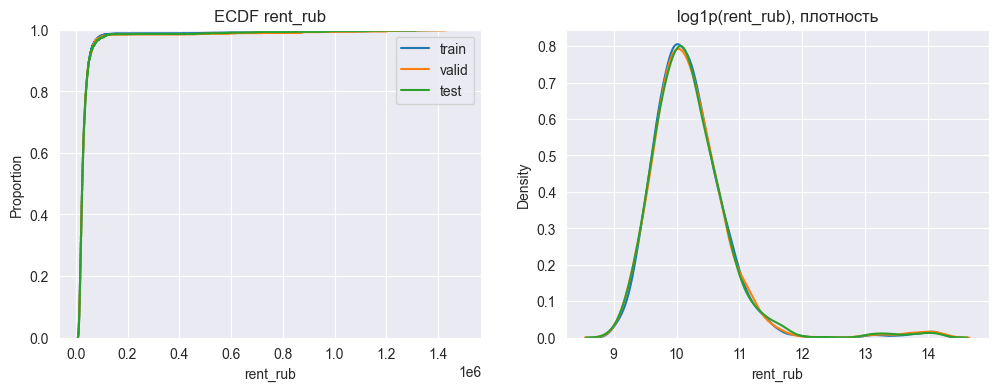

In [7]:
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

# Сравниваем valid и test с train
parts = {"valid": df_valid, "test": df_test}

# Числовые признаки: сравниваем центр (медиану) и долю пропусков. (KS — максимальное расстояние между двумя ECDF(ЭФР) (долями наблюдений ≤ порога))
rows = []
for c in INT_COLS + FLOAT_COLS:
    a = df_train[c].dropna().astype(float)
    for name, part in parts.items():
        b = part[c].dropna().astype(float)
        ks = stats.ks_2samp(a, b)
        rows.append({"столбец": c, "выборка": name, "медиана train": a.median(), "медиана": b.median(), "KS": round(ks.statistic, 3), "p": round(ks.pvalue, 3), "пропуски train, %": round(df_train[c].isna().mean() * 100, 2), "пропуски, %": round(part[c].isna().mean() * 100, 2)})
num_cmp = pd.DataFrame(rows)
display(num_cmp.sort_values("KS", ascending=False).head(15))

# Целевая переменная: ECDF(ЭФР) показывает долю объявлений с ценой ≤ порога 
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, part in {"train": df_train, "valid": df_valid, "test": df_test}.items():
    sns.ecdfplot(part["rent_rub"].astype(float), ax=ax[0], label=name)
    sns.kdeplot(np.log1p(part["rent_rub"].astype(float)), ax=ax[1], label=name)
ax[0].set_title("ECDF rent_rub"); ax[1].set_title("log1p(rent_rub), плотность")
ax[0].legend()
plt.show()

Вывод: разбиение случайно, видно, что KS-статистика и доли малы, значит выборки сопоставимы. Распределение целевой переменной на всех трёх кусках данных совпадает.

## 3. Аудит
Аудит проводится только на train: его результаты определяют правила, которые записываются в Pipeline

In [8]:
import sys
sys.path.insert(0, str(Path("..").resolve()))

TARGET = "rent_rub"  # целевая
ID_COLS = ["listing_id"]
EXCLUDE = ["response_time_hours"]  # не используем инфа после публикации(утечка)
NUM_FEATURES = [c for c in INT_COLS + FLOAT_COLS if c not in [TARGET] + EXCLUDE] # Все численные категории
CAT_FEATURES = [c for c in CAT_COLS if c not in EXCLUDE] # Все использумые категории
FEATURES = NUM_FEATURES + CAT_FEATURES

# x — признаки, y — цель
X_train, y_train = df_train[FEATURES], df_train[TARGET].astype(float)
X_valid, y_valid = df_valid[FEATURES], df_valid[TARGET].astype(float)
num_train = X_train[NUM_FEATURES].astype(float)
print("Признаков:", len(FEATURES), "| числовых:", len(NUM_FEATURES), "| категориальных:", len(CAT_FEATURES))

Признаков: 22 | числовых: 12 | категориальных: 10


### 3.1 Паспорт данных

In [9]:
passport = pd.DataFrame({
    "тип": df_train.dtypes.astype(str),
    "пропусков": df_train.isna().sum(),
    "доля пропусков, %": (df_train.isna().mean() * 100).round(2),
    "уникальных": df_train.nunique(dropna=True),
})
display(passport)

print("\nКатегориальные столбцы: сколько раз встречается каждое значение")
for col in CAT_COLS:
    vc = df_train[col].value_counts(dropna=False)
    print(f"\n{col} (категорий: {df_train[col].nunique()}):")
    display(vc.to_frame("количество").assign(доля=lambda t: (t["количество"] / len(df_train) * 100).round(2)))

,тип,пропусков,"доля пропусков, %",уникальных
listing_id,string,0,0.00,8499
publication_date,datetime64[ns],0,0.00,61
district,category,40,0.47,12
house_type,category,0,0.00,5
year_built,Int64,809,9.52,106
floors_total,Int64,0,0.00,26
floor,Int64,0,0.00,27
elevator,category,0,0.00,2
rooms,Int64,0,0.00,6
total_area,float64,0,0.00,998



Категориальные столбцы: сколько раз встречается каждое значение

district (категорий: 12):


,количество,доля
district,,
Советский,900,10.59
Ленинский,838,9.86
Кировский,787,9.26
Заречный,777,9.14
Первомайский,734,8.64
Северный,685,8.06
Октябрьский,665,7.82
Железнодорожный,642,7.55
Центральный,636,7.48



house_type (категорий: 5):


,количество,доля
house_type,,
панельный,3789,44.58
кирпичный,2380,28.00
монолитный,1786,21.01
блочный,490,5.77
деревянный,54,0.64



elevator (категорий: 2):


... (11 outputs left out)


pets_allowed (категорий: 2):


,количество,доля
pets_allowed,,
нет,5533,65.1
да,2966,34.9



seller_type (категорий: 2):


,количество,доля
seller_type,,
собственник,5113,60.16
агентство,3386,39.84


### 3.2 Написание категорий

In [10]:
from difflib import SequenceMatcher
from modules.preprocessing import normalize_text, canon_key

for c in CAT_FEATURES:
    norm = normalize_text(X_train[c])  # пробелы по краям, регистр, повторные пробелы
    key = canon_key(X_train[c])        # ключ: без знаков, ё=е, латиница -> кириллица
    counts = norm.value_counts()       # частоты нормализованных написаний
    print(f"\n{c}: значений {X_train[c].nunique()} -> после нормализации {norm.nunique()} -> по ключу {key.nunique()}")

    # Написания, которые отличаются только знаками, ё/е или латиницей: ключ у них общий
    groups = pd.DataFrame({"norm": norm, "key": key}).dropna().groupby("key")["norm"].agg(lambda v: sorted(v.unique()))
    same = groups[groups.map(len) > 1]
    if len(same):
        display(same.to_frame("написания с одним ключом"))

    # Похожие, но с разными ключами: вероятные опечатки (решение принимаем вручную)
    vals = list(counts.index)
    keymap = dict(zip(vals, canon_key(pd.Series(vals))))
    similar = [(a, b, round(SequenceMatcher(None, a, b).ratio(), 2)) for i, a in enumerate(vals) for b in vals[i + 1:] if keymap[a] != keymap[b] and SequenceMatcher(None, a, b).ratio() >= 0.8]
    if similar:
        display(pd.DataFrame(similar, columns=["написание 1", "написание 2", "сходство"]).assign(частота_1=lambda t: t["написание 1"].map(counts), частота_2=lambda t: t["написание 2"].map(counts)))

    # Полная таблица только для столбцов с большим числом значений
    if norm.nunique() > 6:
        display(counts.to_frame("количество").assign(доля=lambda t: (t["количество"] / len(df_train) * 100).round(2)))


district: значений 12 -> после нормализации 12 -> по ключу 12


,количество,доля
district,,
советский,900,10.59
ленинский,838,9.86
кировский,787,9.26
заречный,777,9.14
первомайский,734,8.64
северный,685,8.06
октябрьский,665,7.82
железнодорожный,642,7.55
центральный,636,7.48



house_type: значений 5 -> после нормализации 5 -> по ключу 5

elevator: значений 2 -> после нормализации 2 -> по ключу 2

renovation: значений 20 -> после нормализации 14 -> по ключу 13


,написания с одним ключом
key,
евроремонт,"[евро-ремонт, евроремонт]"


,написание 1,написание 2,сходство,частота_1,частота_2
0,без ремонта,нет ремонта,0.82,1526,58


,количество,доля
renovation,,
косметический,3198,37.63
евроремонт,2036,23.96
без ремонта,1526,17.96
дизайнерский,714,8.4
косметика,169,1.99
косм.,139,1.64
евро,122,1.44
требует ремонта,96,1.13
евро-ремонт,79,0.93



furniture: значений 3 -> после нормализации 3 -> по ключу 3

appliances: значений 2 -> после нормализации 2 -> по ключу 2

balcony: значений 3 -> после нормализации 3 -> по ключу 3

parking: значений 3 -> после нормализации 3 -> по ключу 3

pets_allowed: значений 2 -> после нормализации 2 -> по ключу 2

seller_type: значений 2 -> после нормализации 2 -> по ключу 2


#### 3.2.1 Объединение названий категорий

In [11]:
from modules.preprocessing import CategoryCleaner

# Итоговые допустимые значения
VALID_CATEGORIES = {"renovation": ["евроремонт", "косметический", "без ремонта", "дизайнерский"]}

# Словари замен названий
CATEGORY_FIXES = {"renovation": {
    "косметика": "косметический",
    "косметический ремонт": "косметический",
    "дизайнерский ремонт": "дизайнерский",
    "нет ремонта": "без ремонта",     
    "требует ремонта": "без ремонта",
    "авторский": "дизайнерский",
}}

# Экземпляр "очистителя" обучаем на train
cleaner = CategoryCleaner(CAT_FEATURES, CATEGORY_FIXES, VALID_CATEGORIES).fit(X_train)
X_clean = cleaner.transform(X_train)  # новая таблица, X_train не изменился

display(X_clean["renovation"].value_counts(dropna=False).to_frame("количество"))
# Ищем знач не из VALID_CATEGORIES
left = X_clean["renovation"].value_counts().loc[lambda s: ~s.index.isin(VALID_CATEGORIES["renovation"])]
print("Неопознанные значения:"); display(left.to_frame("количество"))

add_log("renovation", "разные написания одной категории", "train, valid, test",
        int((X_train["renovation"].astype("string").str.strip().str.lower() != X_clean["renovation"]).sum()),
        "20 написаний", "нормализация + сопоставление с допустимыми + CATEGORY_FIXES",
        f"{X_clean['renovation'].nunique()} категорий", "OneHotEncoder не должен считать синонимы разными категориями")

,количество
renovation,
косметический,3549
евроремонт,2237
без ремонта,1680
дизайнерский,806
NaN,227


Неопознанные значения:


,количество
renovation,


### 3.3 Проверяем числовые признаки

In [12]:
checks = pd.Series({
    "kitchen_area | living_area | total_area < 0" : (df_train["living_area"]<0).sum() + (df_train["kitchen_area"]<0).sum() + (df_train["total_area"]<0).sum(),
    "floor < 1": (df_train["floor"] < 1).sum(),
    "floors_total < 1": (df_train["floors_total"] < 1).sum(),
    "floor > floors_total": (df_train["floor"] > df_train["floors_total"]).sum(),
    "living_area > total_area": (df_train["living_area"] > df_train["total_area"]).sum(),
    "kitchen_area > total_area": (df_train["kitchen_area"] > df_train["total_area"]).sum(),
    "living + kitchen > total": ((df_train["living_area"] + df_train["kitchen_area"]) > df_train["total_area"]).sum(),
    "year_built < 1800": (df_train["year_built"] < 1800).sum(),
    "year_built > 2026": (df_train["year_built"] > 2026).sum(),
    "площадь <= 0": (df_train[["total_area", "living_area", "kitchen_area"]] <= 0).any(axis=1).sum(),
    "metro_distance_m < 0": (df_train["metro_distance_m"] < 0).sum(),
    "distance_to_center_km > 50": (df_train["distance_to_center_km"] > 50).sum(),
    "rent_rub <= 0": (df_train[TARGET] <= 0).sum(),
})
display(checks.to_frame("строк"))
print("Диапазон дат:", df_train["publication_date"].min(), "—", df_train["publication_date"].max())

display(df_train.loc[df_train["distance_to_center_km"] > 50, ["distance_to_center_km", "district", "metro_distance_m"]].head(10))
display(df_train.loc[df_train["floors_total"] < 1, ["floors_total", "floor", "house_type", "year_built"]].head(10))
display(df_train.loc[df_train["living_area"] > df_train["total_area"], ["living_area", "kitchen_area", "total_area"]].head(10))


NUM_BOUNDS = {"floor": (1, None), "year_built": (1800, 2026), "total_area": (1, None), "living_area": (1, None), "kitchen_area": (1, None), "ceiling_height": (2, 6), "metro_distance_m": (0, None), "distance_to_center_km": (0, None)}
NUM_PAIRS = [("floor", "floors_total"), ("living_area", "total_area"), ("kitchen_area", "total_area")]

,строк
kitchen_area | living_area | total_area < 0,0
floor < 1,0
floors_total < 1,238
floor > floors_total,269
living_area > total_area,26
kitchen_area > total_area,0
living + kitchen > total,179
year_built < 1800,0
year_built > 2026,0
площадь <= 0,0


Диапазон дат: 2026-09-01 00:00:00 — 2026-10-31 00:00:00


,distance_to_center_km,district,metro_distance_m
9428,8800.0,Южный,7350
9773,8100.0,Кировский,480
9008,5400.0,Первомайский,1060
7060,12800.0,Северный,3980
10251,10800.0,Южный,4670
3261,6300.0,Заречный,1520
11779,3600.0,Октябрьский,1460
6679,7300.0,Советский,700
6810,3900.0,Октябрьский,540
400,1400.0,Центральный,850


,floors_total,floor,house_type,year_built
262,0,17,кирпичный,2016
4824,0,8,панельный,1979
5810,0,5,кирпичный,1985
1519,0,3,панельный,<NA>
685,0,1,кирпичный,1964
2650,0,14,панельный,1973
3499,0,2,кирпичный,<NA>
4298,0,13,монолитный,2019
5899,0,21,кирпичный,2019
10133,0,5,панельный,2016


,living_area,kitchen_area,total_area
7147,83.3,8.5,60.0
5213,104.7,10.5,93.5
7059,59.7,6.5,44.8
7710,55.8,7.7,50.8
1892,65.9,5.2,59.0
11069,84.5,7.0,76.2
8575,60.3,7.4,54.0
6283,93.5,8.7,68.3
1473,79.1,7.0,67.5
6101,66.3,9.4,50.0


#### 3.3.1 Числовая очистка

In [13]:
from modules.preprocessing import NumericCleaner

# проверяем очистку на отдельной копии train
num_cleaner = NumericCleaner(NUM_FEATURES, NUM_BOUNDS, NUM_PAIRS)
X_num_clean = num_cleaner.fit_transform(X_train)

# Маски считаем по данным ДО очистки
meters_mask = X_train["distance_to_center_km"] > 50
zero_floors_mask = X_train["floors_total"] == 0

# Все расстояния, которые изменятся, и результат деления
display(pd.DataFrame({
        "было": X_train.loc[meters_mask, "distance_to_center_km"],
        "стало, км": X_num_clean.loc[meters_mask, "distance_to_center_km"],
    }).sort_values("было"))

# Проверяем новые пропуски в числовых признаках
new_na = X_train[NUM_FEATURES].notna() & X_num_clean[NUM_FEATURES].isna()
display(new_na.sum().loc[lambda s: s > 0].to_frame("новых пропусков"))

# Показываем площади после применения правил
area_mask = X_train["living_area"] > X_train["total_area"]
display(X_num_clean.loc[ area_mask, ["living_area", "kitchen_area", "total_area"]].head(10))

# объединяем обе очистки в одной таблице
X_clean = cleaner.transform(X_num_clean)

,было,"стало, км"
3510,400.0,0.4
11458,500.0,0.5
3118,900.0,0.9
400,1400.0,1.4
11634,1500.0,1.5
...,...,...
8888,14100.0,14.1
3941,15000.0,15.0
5007,15200.0,15.2
4739,15400.0,15.4


,новых пропусков
floors_total,238
floor,31
living_area,180
kitchen_area,154


,living_area,kitchen_area,total_area
7147,NaN,8.5,60.0
5213,NaN,10.5,93.5
7059,NaN,6.5,44.8
7710,NaN,7.7,50.8
1892,NaN,5.2,59.0
11069,NaN,7.0,76.2
8575,NaN,7.4,54.0
6283,NaN,8.7,68.3
1473,NaN,7.0,67.5
6101,NaN,9.4,50.0


#### 3.3.2 Записываем решения в журнал

In [14]:
# фиксируем принятое правило перевода единиц
add_log("distance_to_center_km", "предполагаемое смешение метров и километров", "train", int(meters_mask.sum()), "значения > 50", "деление на 1000 внутри NumericCleaner", "расстояние в километрах", "принята гипотеза: значения > 50 записаны в метрах; проверяется по таблице до/после")

# ноль -> неизвестная этажность
add_log("floors_total", "нулевая этажность", "train", int(zero_floors_mask.sum()), "0", "замена на NaN внутри NumericCleaner", "пропуск", "нулевая этажность трактуется как неизвестная; строки и остальные признаки сохраняются")

# фиксируем новые пропуски от остальных числовых правил
for c in NUM_FEATURES:
    mask = new_na[c].copy()
    # Нулевую этажность уже записали отдельно
    if c == "floors_total":
        mask &= ~zero_floors_mask.fillna(False)

    n = int(mask.sum())
    if n:
        add_log(c, "нарушение допустимого диапазона или отношения признаков", "train", n, str(X_train.loc[mask, c].head(5).tolist()), "замена на NaN внутри NumericCleaner",  "пропуск",  "правила NUM_BOUNDS и NUM_PAIRS; в паре сохраняем опорное поле, недопустимое зависимое значение считаем неизвестным")

# отдельная неоднозначность: пока без автоматической замены
area_sum_mask = ((X_train["living_area"] <= X_train["total_area"])
               & (X_train["kitchen_area"] <= X_train["total_area"])
               & (X_train["living_area"] + X_train["kitchen_area"]> X_train["total_area"]))

add_log("living_area + kitchen_area", "сумма площадей больше общей после остальных проверок", "train", int(area_sum_mask.sum()),  "living_area + kitchen_area > total_area", "living_area и kitchen_area заменены на NaN", "общая площадь сохранена", "невозможно надёжно определить ошибочную составляющую; обе составляющие считаем неизвестными")


### 3.4 Проверяем результаты

In [15]:
# общий результат очистки
missing = pd.DataFrame({
    "пропусков до": X_train.isna().sum(),
    "новых пропусков": (X_train.notna() & X_clean.isna()).sum(),
    "пропусков после": X_clean.isna().sum(),
})
display(missing)

checks_after = pd.Series({
    "floors_total == 0": (X_clean["floors_total"] == 0).sum(),
    "floor > floors_total": (X_clean["floor"] > X_clean["floors_total"]).sum(),
    "living_area > total_area": (X_clean["living_area"] > X_clean["total_area"]).sum(),
    "kitchen_area > total_area": (X_clean["kitchen_area"] > X_clean["total_area"]).sum(),
    "living + kitchen > total": ((X_clean["living_area"] + X_clean["kitchen_area"]) > X_clean["total_area"]).sum(),
    "distance_to_center_km > 50": (X_clean["distance_to_center_km"] > 50).sum(),
})
display(checks_after.to_frame("нарушений после очистки"))
print("Строк до / после:", len(X_train), "/", len(X_clean))
# Если один из участников пары неизвестен, сравнить их нельзя
print("Неизвестная этажность:", X_clean["floors_total"].isna().sum())
print("Неизвестная жилая площадь:", X_clean["living_area"].isna().sum())

display(X_train.loc[X_clean["living_area"]+X_clean["kitchen_area"]  > X_clean["total_area"], ["living_area", "kitchen_area", "total_area"]].head(10))

,пропусков до,новых пропусков,пропусков после
year_built,809,0,809
floors_total,0,238,238
floor,0,31,31
rooms,0,0,0
metro_distance_m,0,0,0
photos_count,155,0,155
max_tenants,151,0,151
total_area,0,0,0
living_area,510,180,690
kitchen_area,615,154,769


,нарушений после очистки
floors_total == 0,0
floor > floors_total,0
living_area > total_area,0
kitchen_area > total_area,0
living + kitchen > total,0
distance_to_center_km > 50,0


Строк до / после: 8499 / 8499
Неизвестная этажность: 238
Неизвестная жилая площадь: 690


,living_area,kitchen_area,total_area


Вывод: после очистки нарушений нет

### 3.5 Распределения числовых признаков


,известно,min,25%,медиана,75%,max,асимметрия
year_built,7690,1920.0,1970.00,1985.00,2011.00,2025.00,-0.31
floors_total,8261,1.0,5.00,10.00,14.00,25.00,0.58
floor,8468,1.0,3.00,5.00,8.00,25.00,1.24
rooms,8499,0.0,1.00,2.00,2.00,5.00,0.42
metro_distance_m,8499,80.0,690.00,1310.00,4480.00,9000.00,1.05
photos_count,8344,0.0,6.00,8.00,12.00,28.00,0.53
max_tenants,8348,1.0,2.00,3.00,4.00,7.00,0.36
total_area,8499,15.7,36.20,47.30,62.10,171.60,1.32
living_area,7809,10.7,20.60,26.50,35.60,107.50,1.47
kitchen_area,7730,4.0,6.70,8.50,10.60,23.70,0.98


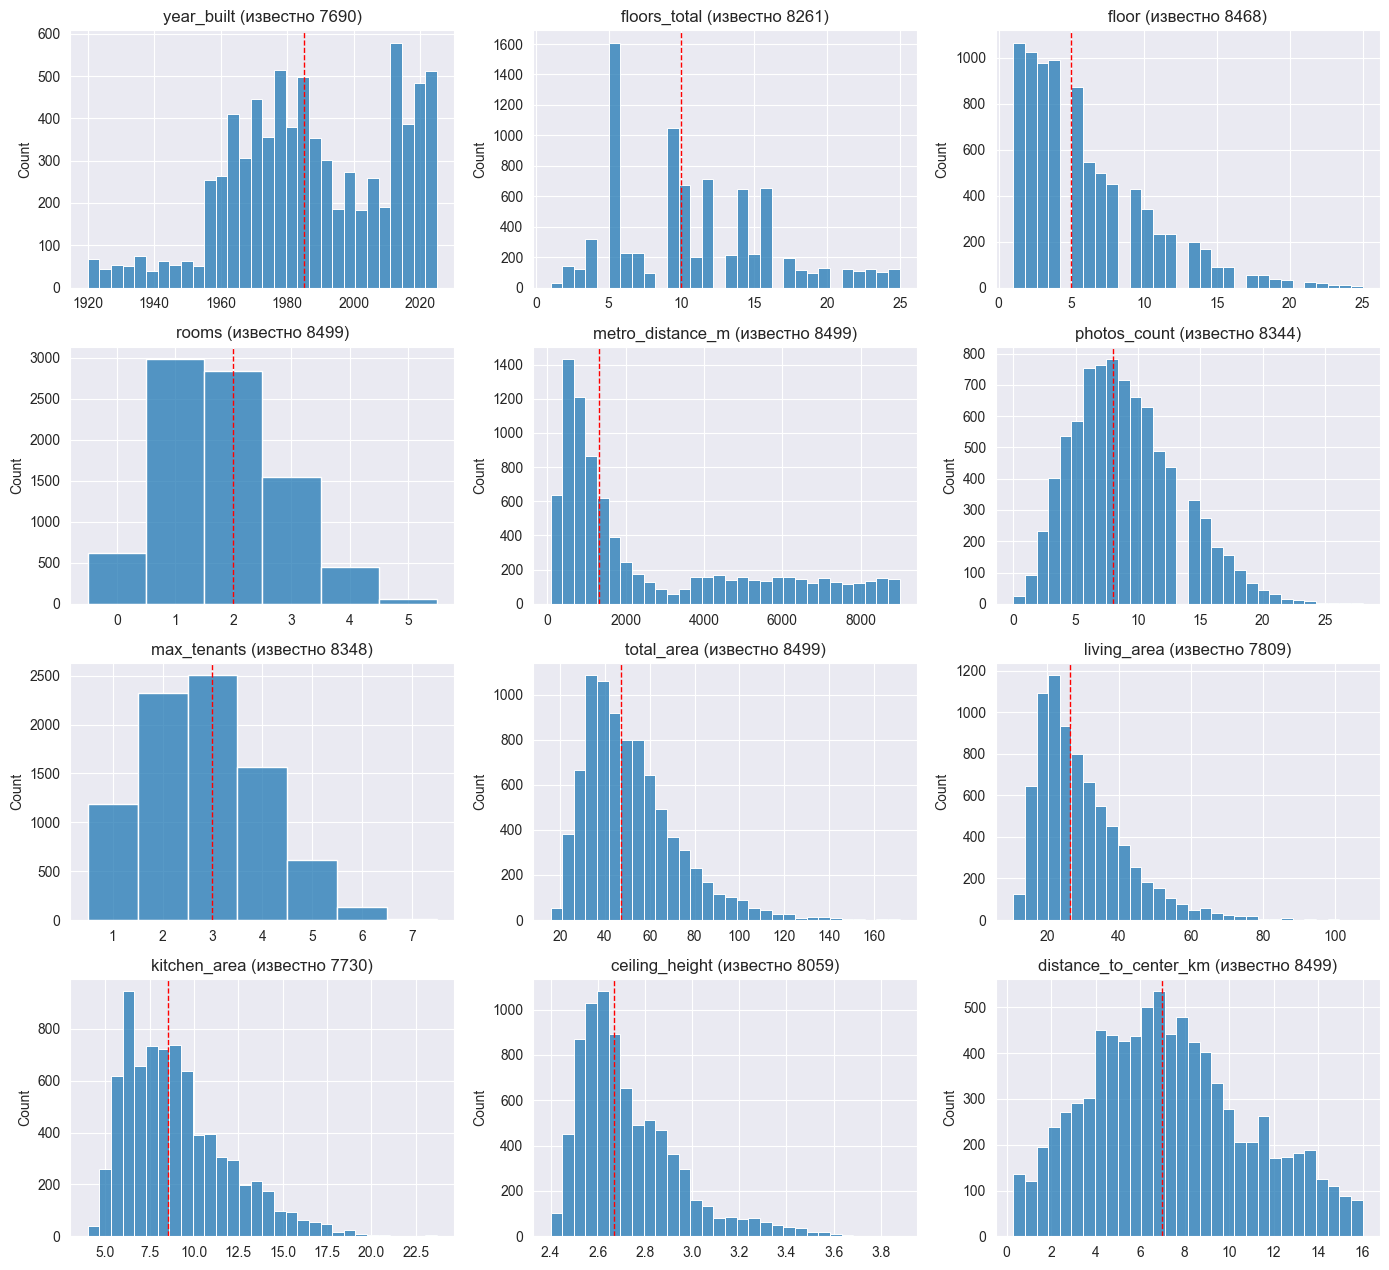

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Только известные значения после очистки (пропуски пока не заполняем)
num_clean = X_clean[NUM_FEATURES].astype(float)

# Таблица: сколько значений известно и как устроено распределение
dist = pd.DataFrame({
    "известно": num_clean.notna().sum(),
    "min": num_clean.min(),
    "25%": num_clean.quantile(0.25),
    "медиана": num_clean.median(),
    "75%": num_clean.quantile(0.75),
    "max": num_clean.max(),
    "асимметрия": num_clean.skew(),   # > 0 — правый хвост, < 0 — левый
})
display(dist.round(2))

# Признаки с малым числом значений рисуем столбцами по значениям
DISCRETE = ["rooms", "max_tenants"]

n_cols = 3
n_rows = int(np.ceil(len(NUM_FEATURES) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 3.2 * n_rows))
axes = axes.ravel()

for ax, c in zip(axes, NUM_FEATURES):
    data = num_clean[c].dropna()
    sns.histplot(data, bins=30, discrete=(c in DISCRETE), ax=ax)
    ax.axvline(data.median(), color="red", linestyle="--", linewidth=1)  # красная линия — медиана
    ax.set_title(f"{c} (известно {len(data)})")
    ax.set_xlabel("")

# Пустые ячейки сетки скрываем
for ax in axes[len(NUM_FEATURES):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Вывод:
- total_area, living_area, kitchen_area — правосторонняя асимметрия (много маленьких квартир, хвост вправо).
- rooms, max_tenants — дискретные.
- ceiling_height — явный пик на ~2.6 (стандарт).
- metro_distance_m — бимодальное (или с длинным хвостом).

### 3.6 Распределение целевой переменной и её связь с остальными числовыми признаками

,Spearman с rent_rub
total_area,0.693
living_area,0.665
rooms,0.567
max_tenants,0.465
distance_to_center_km,-0.461
ceiling_height,0.397
kitchen_area,0.387
metro_distance_m,-0.295
photos_count,0.223
year_built,0.143


,count,median
district,,
Промышленный,605,18000.0
Северный,685,20000.0
Южный,566,20000.0
Железнодорожный,642,20500.0
Лесной,624,21500.0
Первомайский,734,23000.0
Кировский,787,25000.0
Заречный,777,26000.0
Советский,900,26500.0


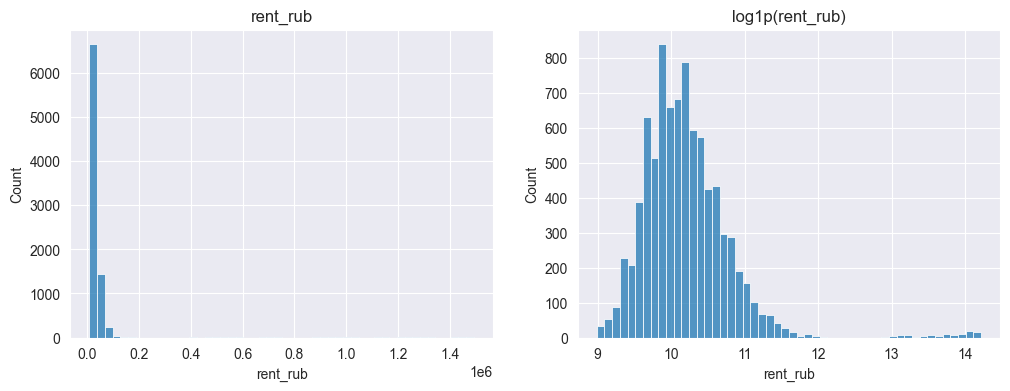

In [17]:
# анализируем уже очищенные числа
num_train = X_clean[NUM_FEATURES].astype(float)
display(num_train.corrwith(y_train, method="spearman").sort_values(key=abs, ascending=False).round(3).to_frame("Spearman с rent_rub"))
display(df_train.groupby("district", observed=True)[TARGET].agg(["count", "median"]).sort_values("median"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y_train, bins=50, ax=ax[0])
sns.histplot(np.log1p(y_train), bins=50, ax=ax[1])
ax[0].set_title("rent_rub")
ax[1].set_title("log1p(rent_rub)")
plt.show()

Вывод: 
- сильная правая асимметрия, при log приближается к нормальному распределению
- Спирмен с rent_rub: самые сильные монотонные связи - total_area, living_area и rooms

## 4. Анализ и обработка пропусков
### 4.1 Подготовка данных для анализа пропусков
Применяем только категориальную и числовую очистку

In [18]:
from modules.preprocessing import NumericCleaner, CategoryCleaner

# Параметры и правила берём из главы 3
num_cleaner = NumericCleaner(NUM_FEATURES, NUM_BOUNDS, NUM_PAIRS)
cleaner = CategoryCleaner(CAT_FEATURES, CATEGORY_FIXES, VALID_CATEGORIES)

X_num_clean = num_cleaner.fit_transform(X_train)
X_clean = cleaner.fit_transform(X_num_clean)

# Validation: только transform, без обучения новых соответствий
X_valid_clean = num_cleaner.transform(X_valid)
X_valid_clean = cleaner.transform(X_valid_clean)

print("Строк train:", len(X_clean))
print("Строк valid:", len(X_valid_clean))

Строк train: 8499
Строк valid: 1822


### 4.2 Сколько пропусков и происхождение

In [19]:
missing = pd.DataFrame({
    "до очистки": X_train.isna().sum(),
    "добавлено очисткой": (X_train.notna() & X_clean.isna()).sum(),
    "после очистки": X_clean.isna().sum(),
    "после, %": (X_clean.isna().mean() * 100).round(2),
})
display(missing.sort_values("после очистки", ascending=False))

print("Строк хотя бы с одним пропуском:", X_clean.isna().any(axis=1).sum())
print("Полных строк:", X_clean.notna().all(axis=1).sum())
print("Потеряли бы при dropna, %:", round(X_clean.isna().any(axis=1).mean() * 100, 2))

# Проверяем, нет ли столбца, который полностью пуст
print("Полностью пустые столбцы:", X_clean.columns[X_clean.isna().all()].tolist())

# Сколько пропусков приходится на одну строку
display(X_clean.isna().sum(axis=1).value_counts().sort_index().to_frame("число объявлений"))


,до очистки,добавлено очисткой,после очистки,"после, %"
year_built,809,0,809,9.52
kitchen_area,615,154,769,9.05
living_area,510,180,690,8.12
ceiling_height,440,0,440,5.18
balcony,357,0,357,4.20
parking,263,0,263,3.09
floors_total,0,238,238,2.80
renovation,227,0,227,2.67
furniture,227,0,227,2.67
photos_count,155,0,155,1.82


Строк хотя бы с одним пропуском: 3452
Полных строк: 5047
Потеряли бы при dropna, %: 40.62
Полностью пустые столбцы: []


,число объявлений
0,5047
1,2632
2,706
3,103
4,11


Вывод: если удалять все строки с пропусками, то потеряем 40% выборки - не подходит. Нужно изучить: есть ли закономерности(связь) между признаками и целевой переменной

## 4.3 Пропуски и стоимость аренды
Посмотрим есть ли явная связь между значением целевой переменной и пропусками в разных признаках

In [20]:
missing_cols = missing.index[missing["после очистки"] > 0].tolist()

for c in missing_cols:
    temp = pd.DataFrame({ "есть пропуск": X_clean[c].isna(), "rent_rub": y_train,})
    
    # Считаем метрики
    stats = temp.groupby("есть пропуск")["rent_rub"].agg(["count", "median", "mean"]).round(2)
    quantiles = temp.groupby("есть пропуск")["rent_rub"].quantile([0.25, 0.75]).unstack().round(2)
    
    # Объединяем в одну таблицу
    combined_table = pd.concat([stats, quantiles], axis=1)
    
    print(f"\n{c} | False — известно, True — пропуск")
    display(combined_table)


year_built | False — известно, True — пропуск


,count,median,mean,0.25,0.75
есть пропуск,,,,,
False,7690,25000.0,40688.1,18500.0,35500.0
True,809,25500.0,41640.3,17500.0,37500.0



floors_total | False — известно, True — пропуск


,count,median,mean,0.25,0.75
есть пропуск,,,,,
False,8261,25000.0,40936.02,18000.0,35500.0
True,238,26000.0,35319.33,19125.0,36375.0



floor | False — известно, True — пропуск


,count,median,mean,0.25,0.75
есть пропуск,,,,,
False,8468,25000.0,40670.47,18000.0,35500.0
True,31,25500.0,70354.84,16250.0,35750.0


... (16 outputs left out)


balcony | False — известно, True — пропуск


,count,median,mean,0.25,0.75
есть пропуск,,,,,
False,8142,25000.0,40540.84,18000.0,35500.0
True,357,26000.0,46204.48,18500.0,36000.0



parking | False — известно, True — пропуск


,count,median,mean,0.25,0.75
есть пропуск,,,,,
False,8236,25000.0,40731.73,18000.0,35500.0
True,263,25000.0,42250.95,18250.0,35000.0


Вывод: 
- самая сильная закономерность(связь) в площади кухни, если не указана площадь кухни цена сильно снижается(по медиане) относительно квартир, где площадь кухни указана. 
- ceiling_height, balcony, furniture — при пропуске цена чуть выше по среднему, а по медиане различий практически нет.
- photos_count, district — при пропуске цена ниже.

## 4.4 Связи числовых признаков

In [21]:
# Связи с целевой переменной и между признаками
num_train = X_clean[NUM_FEATURES].astype(float)

display(num_train.corrwith(y_train, method="spearman")
        .sort_values(key=abs, ascending=False).round(3)
        .to_frame("Spearman с rent_rub"))

corr = num_train.corr(method="spearman")
rows = []
for i, a in enumerate(NUM_FEATURES):
    for b in NUM_FEATURES[i + 1:]:
        if abs(corr.loc[a, b]) >= 0.8:
            rows.append({"признак 1": a, "признак 2": b, "Spearman": round(corr.loc[a, b], 3), "известны оба": int(num_train[[a, b]].notna().all(axis=1).sum()),})
display(pd.DataFrame(rows, columns=["признак 1", "признак 2", "Spearman", "известны оба"]))

,Spearman с rent_rub
total_area,0.693
living_area,0.665
rooms,0.567
max_tenants,0.465
distance_to_center_km,-0.461
ceiling_height,0.397
kitchen_area,0.387
metro_distance_m,-0.295
photos_count,0.223
year_built,0.143


,признак 1,признак 2,Spearman,известны оба
0,rooms,max_tenants,0.805,8348
1,rooms,total_area,0.888,8499
2,rooms,living_area,0.827,7809
3,total_area,living_area,0.942,7809


Вывод: признаки rooms, максимальное число жильцов и площади имеют сильную связь, поэтому их потом надо проверить на мультиколлинеарность и возможно вывести из них новые признаки, например, оставить только доли площадей.
Решение: рассчитать VIF для диагностики мультиколлинеарности

### 4.5 Анализ исходных пропусков кухни

In [22]:
# Маски строим до заполнения
kitchen_original_missing = X_train["kitchen_area"].isna()
kitchen_added_missing = X_train["kitchen_area"].notna() & X_clean["kitchen_area"].isna()

print("Исходных пропусков кухни:", kitchen_original_missing.sum())
print("Добавлено очисткой:", kitchen_added_missing.sum())
print("Число квартир с нулевым количеством комнат: ", (X_clean["rooms"]==0).sum())

# Гипотезу об исходных пропусках проверяем отдельно
kitchen_analysis = pd.DataFrame({
    "rooms": X_clean["rooms"],
    "исходный пропуск кухни": kitchen_original_missing,
    "total_area": X_clean["total_area"],
})
display(kitchen_analysis.groupby("rooms").agg(объявлений=("исходный пропуск кухни", "size"), исходных_пропусков=("исходный пропуск кухни", "sum"), доля_пропусков=("исходный пропуск кухни", "mean")).assign(доля_пропусков=lambda t: (t["доля_пропусков"] * 100).round(2)))

# Сравниваем три группы, не смешивая причины неизвестности
status = pd.Series("известна после очистки", index=X_clean.index)
status.loc[kitchen_original_missing] = "исходный пропуск"
status.loc[kitchen_added_missing] = "добавлено очисткой"
kitchen_groups = pd.DataFrame({"статус кухни": status, "total_area": X_clean["total_area"]})
display(kitchen_groups.groupby("статус кухни")["total_area"].agg(["count", "median", "mean"]).round(2))

Исходных пропусков кухни: 615
Добавлено очисткой: 154
Число квартир с нулевым количеством комнат:  615


,объявлений,исходных_пропусков,доля_пропусков
rooms,,,
0.0,615,615,100.0
1.0,2988,0,0.0
2.0,2844,0,0.0
3.0,1548,0,0.0
4.0,448,0,0.0
5.0,56,0,0.0


,count,median,mean
статус кухни,,,
добавлено очисткой,154,34.6,35.52
известна после очистки,7730,49.7,54.00
исходный пропуск,615,25.6,25.98


Вывод: : пропуски в площади кухни встречаются исключительно при rooms == 0. Это означает, что такие объекты — студии без выделенной кухни

Решение: 
Для студий (rooms == 0): заполняем пропуск площади кухни нулем и создаем бинарный флаг


#### 4.5.1 Заполняем часть пропусков кухни нулями
Зафиксированным правилом в KitchenZeroFiller, изначальные пропуски площади кухни встречаются только у студий (rooms == 0), поэтому потоваим им значение 0.

In [23]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from modules.preprocessing import NumericCleaner, CategoryCleaner, KitchenZeroFiller

# Очистка и технические нули кухни у студий (rooms == 0); доли и жильцов пока не заполняем
base_pipeline = Pipeline([
    ("numeric_cleaner", NumericCleaner(NUM_FEATURES, NUM_BOUNDS, NUM_PAIRS)),
    ("category_cleaner", CategoryCleaner(CAT_FEATURES, CATEGORY_FIXES, VALID_CATEGORIES)),
    ("kitchen_zero", KitchenZeroFiller()),
])
X_base = base_pipeline.fit_transform(X_train)
print("Нулей кухни поставлено студиям:", int(X_base["kitchen_area_original_missing"].sum()))


Нулей кухни поставлено студиям: 615


### 4.6 Пропуски численных признаков связанных с площадь
### 4.6.1 Мультиколлинеарность до заполнения

Полных строк для VIF: 7673


,все пять,без rooms,без max_tenants,без total_area,без living_area,без kitchen_area
kitchen_area,1.24,1.23,1.24,1.18,1.20,NaN
living_area,10.73,10.66,10.73,2.94,NaN,10.35
max_tenants,3.07,2.08,NaN,3.07,3.07,3.07
rooms,6.33,NaN,4.29,5.15,6.29,6.27
total_area,15.51,12.62,15.51,NaN,4.25,14.77


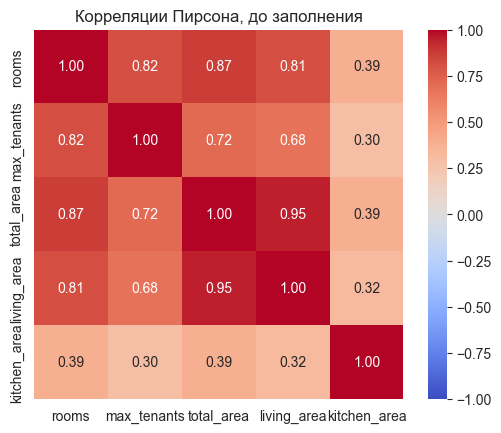

In [24]:
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calc_vif(data):
    matrix = add_constant(data.astype(float), has_constant="add")
    return pd.Series([variance_inflation_factor(matrix.to_numpy(), i) for i in range(1, matrix.shape[1])], index=data.columns)

def vif_by_subset(data):
    """VIF для пяти признаков и после исключения каждого по одному (только полные строки)."""
    complete = data.dropna()
    result = {"все пять": calc_vif(complete)}
    for col in AREA_COLS:
        result[f"без {col}"] = calc_vif(complete.drop(columns=col))
    return pd.DataFrame(result)

AREA_COLS = ["rooms", "max_tenants", "total_area", "living_area", "kitchen_area"]

vif_before = vif_by_subset(X_base[AREA_COLS])
print("Полных строк для VIF:", int(X_base[AREA_COLS].notna().all(axis=1).sum()))
display(vif_before.round(2))

# Корреляции пяти признаков до заполнения
sns.heatmap(X_base[AREA_COLS].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Корреляции Пирсона, до заполнения")
plt.show()

Вывод: на полных строках VIF больше 10 у total_area и living_area, то есть связь между всеми 5 признаками, но основная именно между двумя: без total_area VIF living_area падает с 10.7 до 2.9, и в обратную сторону без living_area total_area падает с 15.5 до 4.3. Площадь кухни зависит меньше всего

### 4.6.2 Распределение долей площадей

,living_share,kitchen_share,non_living_share
count,7809.000,7809.000,7809.000
mean,0.576,0.169,0.255
std,0.078,0.085,0.092
min,0.449,0.000,-0.000
25%,0.511,0.119,0.195
50%,0.573,0.164,0.258
75%,0.636,0.220,0.321
max,0.801,0.525,0.485


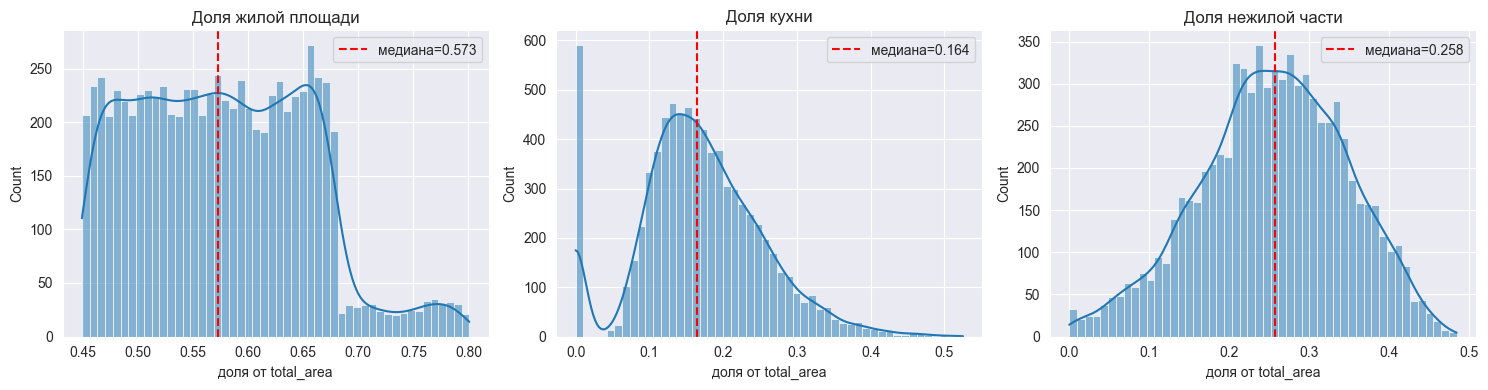

Медианные доли по числу комнат:


,living_share,kitchen_share,non_living_share
rooms,,,
0,0.723,0.000,0.277
1,0.561,0.228,0.203
2,0.561,0.160,0.269
3,0.571,0.122,0.300
4,0.571,0.095,0.331
5,0.573,0.078,0.341


In [25]:
# Доли площадей от общей — на полных строках (без пропусков)
area_full = X_base[["total_area", "living_area", "kitchen_area"]].dropna()

area_full = area_full.copy()
area_full["living_share"] = area_full["living_area"] / area_full["total_area"]
area_full["kitchen_share"] = area_full["kitchen_area"] / area_full["total_area"]
area_full["non_living_share"] = 1 - area_full["living_share"] - area_full["kitchen_share"]

# Статистика долей
display(area_full[["living_share", "kitchen_share", "non_living_share"]].describe().round(3))

# Распределение долей
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes,
                           ["living_share", "kitchen_share", "non_living_share"],
                           ["Доля жилой площади", "Доля кухни", "Доля нежилой части"]):
    sns.histplot(area_full[col], bins=50, kde=True, ax=ax)
    ax.axvline(area_full[col].median(), color="red", linestyle="--", label=f"медиана={area_full[col].median():.3f}")
    ax.set_title(title)
    ax.set_xlabel("доля от total_area")
    ax.legend()
plt.tight_layout()
plt.show()

# Доли в разрезе числа комнат — чтобы убедиться, что медиана стабильна
print("Медианные доли по числу комнат:")
display(area_full.assign(rooms=X_base.loc[area_full.index, "rooms"].astype(int))
        .groupby("rooms")[["living_share", "kitchen_share", "non_living_share"]]
        .median().round(3))

### 4.6.3 Заполнение площадей и жильцов
- жилая площадь заполняется медианными долями от общей площади, 
- кухонная площадь заполняется по группам медианами в зависимости от числа комнат, 
- max_tenants заполняется модой жильцов при данном количестве комнат

In [26]:
from modules.preprocessing import AreaShareImputer, TenantsFromRoomsFiller

# Жилая площадь и кухня — доли от общей, жильцы — мода при данном числе комнат
filled_pipeline = Pipeline([
    ("base", clone(base_pipeline)),
    ("areas", AreaShareImputer()),
    ("tenants", TenantsFromRoomsFiller()),
])
X_filled = filled_pipeline.fit_transform(X_train)

COLS = ["rooms", "max_tenants", "total_area", "living_area", "kitchen_area"]
display(pd.DataFrame({"до": X_base[COLS].isna().sum(), "после": X_filled[COLS].isna().sum()}))

# Что выучено на train
areas = filled_pipeline.named_steps["areas"]
tenants = filled_pipeline.named_steps["tenants"]
print("Жилая площадь: медианная доля от общей", round(areas.living_share_, 3))
display(areas.kitchen_by_rooms_.round(2).to_frame("медиана кухни, м²").rename_axis("число комнат"))
print("Общая медиана кухни (запасная):", round(areas.kitchen_global_, 2))

display(pd.DataFrame({"мода жильцов по комнатам": tenants.tenants_by_rooms_, "медиана жильцов по комнатам": tenants.tenants_by_rooms_,"общая мода жильцов": tenants.tenants_global_}).rename_axis("число комнат"))

# Заполнение не должно сильно менять связи между признаками
vif_after = vif_by_subset(X_filled[COLS])
print("Макс. изменение |корреляции|:", round((X_filled[COLS].corr().abs() - X_base[COLS].corr().abs()).abs().max().max(), 3))
display(pd.concat({"до": vif_before, "после": vif_after}, axis=1).round(2))

,до,после
rooms,0,0
max_tenants,151,0
total_area,0,0
living_area,690,0
kitchen_area,154,0


Жилая площадь: медианная доля от общей 0.573


,"медиана кухни, м²"
число комнат,
1.0,8.20
2.0,8.40
3.0,8.60
4.0,9.20
5.0,11.15


Общая медиана кухни (запасная): 8.5


,мода жильцов по комнатам,медиана жильцов по комнатам,общая мода жильцов
число комнат,,,
0.0,1.0,1.0,3.0
1.0,2.0,2.0,3.0
2.0,3.0,3.0,3.0
3.0,4.0,4.0,3.0
4.0,5.0,5.0,3.0
5.0,6.0,6.0,3.0


Макс. изменение |корреляции|: 0.005


до                                           \
             все пять без rooms без max_tenants без total_area   
kitchen_area     1.24      1.23            1.24           1.18   
living_area     10.73     10.66           10.73           2.94   
max_tenants      3.07      2.08             NaN           3.07   
rooms            6.33       NaN            4.29           5.15   
total_area      15.51     12.62           15.51            NaN   

                                                 после            \
             без living_area без kitchen_area все пять без rooms   
kitchen_area            1.20              NaN     1.23      1.22   
living_area              NaN            10.35    11.57     11.49   
max_tenants             3.07             3.07     3.07      2.08   
rooms                   6.29             6.27     6.36       NaN   
total_area              4.25            14.77    16.35     13.44   

                                                                              
             без max_tenants без total_area без living_area без kitchen_area  
kitchen_area            1.23           1.18            1.19              NaN  
living_area            11.56           3.02             NaN            11.17  
max_tenants              NaN           3.07            3.07             3.07  
rooms                   4.30           5.23            6.32             6.30  
total_area             16.35            NaN            4.27            15.60

Вывод: для 5 признаков(AREA_COLS) пропуски закрыты полностью

### 4.6.4 Влияние на качество моделей

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_predict

cv = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train))
models = {"LinearRegression": LinearRegression(), "Ridge": Ridge(alpha=10)}

def cv_mae(preparation, cols, model):
    """MAE и RMSE в рублях: модель учится на log1p(цены), прогноз возвращаем expm1."""
    pipe = Pipeline([("prep", clone(preparation)), ("select", ColumnTransformer([("cols", "passthrough", cols)], remainder="drop")), ("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("model", clone(model))])
    pred = np.expm1(cross_val_predict(pipe, X_train, np.log1p(y_train), cv=cv))
    err = y_train.to_numpy() - pred
    return np.mean(np.abs(err)), np.sqrt(np.mean(err ** 2))

# Dummy считаем тем же способом
dummy_pred = cross_val_predict(DummyRegressor(strategy="median"), np.zeros((len(y_train), 1)), y_train, cv=cv)
dummy_mae = np.mean(np.abs(y_train.to_numpy() - dummy_pred))

area_sets = {"все пять": AREA_COLS, "без living_area": [c for c in AREA_COLS if c != "living_area"], "площадь, комнаты и кухня": ["total_area", "rooms", "kitchen_area"]}
preparations = {"базовая медиана": base_pipeline, "доли и моды": filled_pipeline}
rows = [[prep, m, s, *cv_mae(p, cols, model)] for prep, p in preparations.items() for m, model in models.items() for s, cols in area_sets.items()]
res_area = pd.DataFrame(rows, columns=["заполнение", "модель", "набор", "MAE", "RMSE"])
res_area["ΔMAE к Dummy"] = res_area["MAE"] - dummy_mae
print("Dummy MAE:", round(dummy_mae, 2))
display(res_area.sort_values("MAE").round(2))

Dummy MAE: 22743.68


,заполнение,модель,набор,MAE,RMSE,ΔMAE к Dummy
10,доли и моды,Ridge,без living_area,19553.23,112366.32,-3190.44
4,базовая медиана,Ridge,без living_area,19553.79,112366.24,-3189.89
11,доли и моды,Ridge,"площадь, комнаты и кухня",19554.16,112365.14,-3189.51
5,базовая медиана,Ridge,"площадь, комнаты и кухня",19554.29,112365.19,-3189.39
9,доли и моды,Ridge,все пять,19555.51,112366.72,-3188.16
7,доли и моды,LinearRegression,без living_area,19556.41,112368.00,-3187.27
1,базовая медиана,LinearRegression,без living_area,19556.92,112367.91,-3186.76
8,доли и моды,LinearRegression,"площадь, комнаты и кухня",19557.12,112366.78,-3186.56
2,базовая медиана,LinearRegression,"площадь, комнаты и кухня",19557.24,112366.83,-3186.43
3,базовая медиана,Ridge,все пять,19557.97,112366.69,-3185.71


Вывод: различий между способами заполнения и наборами признаков практически нет, все способы лучше Dummy. Отсутствие признаков не ухудшает качество, значит в будующем можно исключить признак для снижения мультиколлинеарности.

## 4.7 Остальные численные пропуски 
### 4.7.1 Что осталось и от чего зависит

In [28]:
# Что осталось неизвестным после заполнения площадей и жильцов
left_missing = X_filled.isna().sum()
missing_cols = left_missing[left_missing > 0].index.tolist()
display(pd.DataFrame({"пропусков": left_missing[missing_cols], "%": (left_missing[missing_cols] / len(X_filled) * 100).round(2)}).sort_values("пропусков", ascending=False))

# На сколько % медианы известных признаков отличаются в строках с пропуском
ref = ["rooms", "total_area", "distance_to_center_km", "metro_distance_m"]
diff = {c: X_filled[ref].astype(float).groupby(X_filled[c].isna()).median().pipe(lambda g: (g.loc[True] / g.loc[False] - 1) * 100) for c in missing_cols}
print("\nНа сколько процентов медианы известных признаков отличаются в строках с пропуском vs строках без пропуска")
display(pd.DataFrame(diff).T.round(1))

# Доля пропусков по типу дома
num_missing = [c for c in missing_cols if c in NUM_FEATURES]
print("\nДоля пропусков (%) в каждом числовом признаке в разрезе типа дома")
display(pd.DataFrame({c: X_filled[c].isna().groupby(X_filled["house_type"], observed=True).mean() * 100 for c in num_missing}).round(1))

,пропусков,%
year_built,809,9.52
ceiling_height,440,5.18
balcony,357,4.20
parking,263,3.09
floors_total,238,2.80
furniture,227,2.67
renovation,227,2.67
photos_count,155,1.82
district,40,0.47
floor,31,0.36



На сколько процентов медианы известных признаков отличаются в строках с пропуском vs строках без пропуска


,rooms,total_area,distance_to_center_km,metro_distance_m
year_built,0.0,3.4,-11.3,-14.2
floors_total,0.0,9.5,11.4,29.2
floor,0.0,-6.7,0.0,-6.1
photos_count,0.0,0.2,1.4,26.7
ceiling_height,0.0,1.7,4.3,-6.8
district,0.0,-5.6,2.9,-14.9
renovation,0.0,3.8,2.9,7.6
furniture,0.0,6.1,-8.5,-15.2
balcony,0.0,0.8,2.9,2.3
parking,0.0,3.8,0.0,-3.1



Доля пропусков (%) в каждом числовом признаке в разрезе типа дома


,year_built,floors_total,floor,photos_count,ceiling_height
house_type,,,,,
блочный,12.4,2.0,0.6,0.4,6.3
деревянный,24.1,3.7,0.0,1.9,5.6
кирпичный,14.3,2.6,0.2,1.9,5.3
монолитный,3.0,3.2,0.5,1.6,5.0
панельный,9.0,2.8,0.4,2.1,5.0


Вывод: строки без года ближе к центру и метро, а в деревянных домах год неизвестен у 24% объявлений


### 4.7.2 Выбор метода на скрытых значениях
Скроем 20% данных и сравним способы из заполнения.

In [36]:
from modules.preprocessing import NumericKNNFiller, FloorsFiller

# Признаки для поиска похожих объектов; тип дома входит 0/1-столбцами
KNN_COLS = ["year_built", "ceiling_height", "floors_total", "floor", "distance_to_center_km", "metro_distance_m"]
KNN_CAT = ["house_type"]

def masking_test(col, share=0.2, k=10, cat_weight=1.0, seed=RANDOM_STATE):
    """Скрываем 20% известных значений и восстанавливаем их разными способами."""
    rng = np.random.default_rng(seed)
    data = X_filled.copy()
    hidden = rng.choice(data.index[data[col].notna()], size=int(data[col].notna().sum() * share), replace=False)
    truth = data.loc[hidden, col].astype(float)
    data.loc[hidden, col] = np.nan

    # Простые способы: общая медиана и медиана по типу дома
    values = data[col].astype(float)
    group = data["house_type"].astype(object)
    result = pd.DataFrame({"истина": truth, "общая медиана": values.median(), "медиана по house_type": group.map(values.groupby(group).median()).astype(float)[hidden]})

    # KNN той же реализацией, что в итоговой цепочке
    features = KNN_COLS if col in KNN_COLS else KNN_COLS + [col]
    knn = NumericKNNFiller([col], features, KNN_CAT, cat_weight, k).fit(data).transform(data)
    result["KNN"] = knn.loc[hidden, col]

    # Правило для этажности: десятилетие постройки и нижняя граница по этажу
    if col == "floors_total":
        result["десятилетие, не меньше этажа"] = FloorsFiller().fit(data).transform(data).loc[hidden, col]
    return result

mae_table = pd.DataFrame({col: {m: (p["истина"] - p[m]).abs().mean() for m in p.columns if m != "истина"} for col, p in ((c, masking_test(c)) for c in ["year_built", "ceiling_height", "floors_total", "photos_count"])})
display(mae_table.round(3))

,year_built,ceiling_height,floors_total,photos_count
общая медиана,20.302,0.159,4.485,3.423
медиана по house_type,14.350,0.138,3.847,3.390
KNN,7.762,0.095,2.352,3.501
"десятилетие, не меньше этажа",NaN,NaN,2.535,NaN


Вывод: KNN ошибается сильно меньше в year_built и ceiling_height, также лучший результат для floors_total, а всё же выберем FloorsFiller, так как он сразу проверяет и гарантирует, что floors_total >= floor. Для photos_count можно взять просто медиану.

### 4.7.3 Итоговая цепочка заполнения численных пропусков
- AreaShareImputer - площади 
- TenantsFromRoomsFiller - жильцы
- KNN - года и потолков 
- FloorsFiller -этажность и этаж 
- медиана - фото

In [49]:
from modules.preprocessing import GroupMedianFiller

# Полная цепочка: площади и жильцы, год и потолки по KNN, этажность и этаж, фото, категории
numeric_pipeline = Pipeline([
    ("filled", clone(filled_pipeline)),
    ("knn", NumericKNNFiller(["year_built", "ceiling_height"], KNN_COLS, KNN_CAT, 1.0, 10)),  # k и вес — из таблицы подбора
    ("floors", FloorsFiller()),
    ("photos", GroupMedianFiller(["photos_count"])),
])
X_full = numeric_pipeline.fit_transform(X_train)
X_valid_full = numeric_pipeline.transform(X_valid)   # validation только преобразуем

### 4.7.4 Проверка заполнения

,до,train после,valid после
year_built,809,0,0
floors_total,238,0,0
floor,31,0,0
photos_count,155,0,0
ceiling_height,440,0,0


Этаж выше этажности: train 0 | valid 0


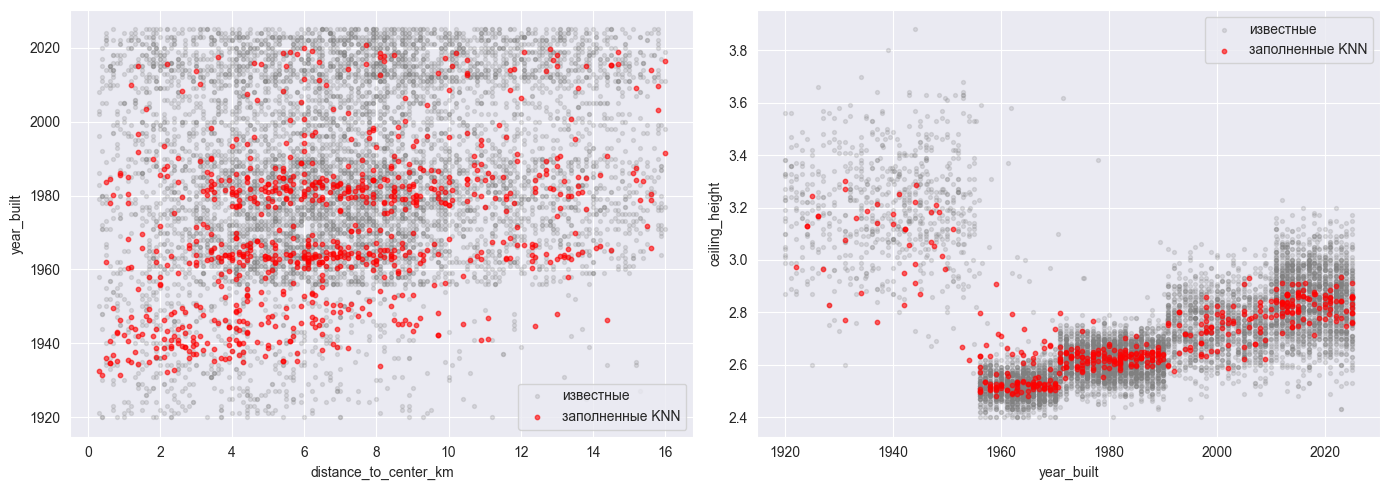

In [50]:
# Проверка: пропуски закрыты, этаж не выше этажности, заполненные точки внутри облака известных
fixed = [c for c in missing_cols if c in NUM_FEATURES]
display(pd.DataFrame({"до": X_filled[fixed].isna().sum(), "train после": X_full[fixed].isna().sum(), "valid после": X_valid_full[fixed].isna().sum()}))
print("Этаж выше этажности: train", int((X_full["floor"] > X_full["floors_total"]).sum()), "| valid", int((X_valid_full["floor"] > X_valid_full["floors_total"]).sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (x, y) in zip(axes, [("distance_to_center_km", "year_built"), ("year_built", "ceiling_height")]):
    was_missing = X_filled[y].isna()
    ax.scatter(X_full.loc[~was_missing, x], X_full.loc[~was_missing, y], alpha=0.2, s=8, color="gray", label="известные")
    ax.scatter(X_full.loc[was_missing, x], X_full.loc[was_missing, y], alpha=0.6, s=10, color="red", label="заполненные KNN")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.legend()
plt.tight_layout()
plt.show()

Вывод: все числовые пропуски закрыты, заполненные(красные) точки лежат внутри облака известных значений

### 4.7.5 Проверяем оставшиеся пропуски

In [72]:
# Сколько пропусков осталось после всей подготовки
remaining = pd.DataFrame({"train": X_full.isna().sum(), "valid": X_valid_full.isna().sum()})
display(remaining[(remaining > 0).any(axis=1)] if remaining.to_numpy().sum() else pd.DataFrame({"итог": ["пропусков не осталось"]}))

# Флаги пропусков, созданные цепочкой
FLAGS = [c for c in X_full.columns if c.endswith("_missing")]
print("Флаги пропусков:", FLAGS)

,train,valid
district,40,12
renovation,227,44
furniture,227,53
balcony,357,72
parking,263,62


Флаги пропусков: ['kitchen_area_original_missing', 'living_area_missing', 'kitchen_area_missing', 'max_tenants_missing', 'year_built_missing', 'ceiling_height_missing', 'floors_total_missing', 'photos_count_missing']


In [52]:
# Журнал: что и чем заполнено
actions = {
    "kitchen_area": "0 для студий; остальные — медианная доля от общей площади",
    "living_area": "медианная доля от общей площади",
    "max_tenants": "мода жильцов при данном числе комнат",
    "rooms": "мода комнат при данном числе жильцов (запасной вариант, в train пропусков нет)",
    "year_built": "KNN по числовым признакам и типу дома",
    "ceiling_height": "KNN по числовым признакам и типу дома",
    "floors_total": "медиана по десятилетию постройки, не меньше этажа",
    "floor": "медиана для этой этажности, не выше этажности",
    "photos_count": "медиана train",
}
for col, action in actions.items():
    before = int(X_clean[col].isna().sum())
    add_log(col, "пропуск после очистки", "train", before, f"пропусков: {before}", action, f"осталось: {int(X_full[col].isna().sum())}", "параметры считаются только по train")

#### 4.7.6 Альтернативный вариант обработки с PCA

In [53]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from modules.preprocessing import AreaPCA

# Сколько независимых направлений в пяти площадных признаках
pca_full = PCA(random_state=RANDOM_STATE).fit(StandardScaler().fit_transform(X_full[AREA_COLS].astype(float)))
explained = pd.DataFrame({"доля дисперсии": pca_full.explained_variance_ratio_, "накопленная": np.cumsum(pca_full.explained_variance_ratio_)}, index=[f"PC{i + 1}" for i in range(len(AREA_COLS))])
display(explained.round(3))
display(pd.DataFrame(pca_full.components_, index=explained.index, columns=AREA_COLS).round(2))   # нагрузки

# Число компонент: минимальное, при котором накопленная доля не меньше 95%
N_PC = int(np.searchsorted(explained["накопленная"].to_numpy(), 0.95) + 1)
print("Берём компонент:", N_PC)

,доля дисперсии,накопленная
PC1,0.724,0.724
PC2,0.164,0.888
PC3,0.078,0.967
PC4,0.026,0.993
PC5,0.007,1.000


,rooms,max_tenants,total_area,living_area,kitchen_area
PC1,0.50,0.45,0.50,0.48,0.26
PC2,-0.09,-0.16,-0.10,-0.17,0.96
PC3,0.17,0.76,-0.38,-0.50,0.02
PC4,0.83,-0.44,-0.06,-0.34,-0.07
PC5,-0.19,0.02,0.77,-0.61,-0.04


Берём компонент: 3


In [54]:
# Альтернативный вариант: та же цепочка, затем PCA по пяти признакам
numeric_pipeline_pca = Pipeline(clone(numeric_pipeline).steps + [("area_pca", AreaPCA(AREA_COLS, n_components=N_PC, random_state=RANDOM_STATE))])
X_full_pca = numeric_pipeline_pca.fit_transform(X_train)
X_valid_full_pca = numeric_pipeline_pca.transform(X_valid)
PC_COLS = numeric_pipeline_pca.named_steps["area_pca"].pc_cols_

# Компоненты не коррелируют, VIF около 1
display(X_full_pca[PC_COLS].corr().round(3))
display(pd.concat({"пять признаков": calc_vif(X_full_pca[AREA_COLS]), "компоненты": calc_vif(X_full_pca[PC_COLS])}).to_frame("VIF").round(2))

# Сравнение на тех же фолдах: исходные пять, компактный набор и PCA с разным числом компонент
rows = []
for k in range(1, len(AREA_COLS) + 1):
    prep_k = Pipeline(clone(numeric_pipeline).steps + [("area_pca", AreaPCA(AREA_COLS, n_components=k, random_state=RANDOM_STATE))])
    for m, model in models.items():
        rows.append(["доли и моды + PCA", m, f"PCA: {k} комп.", *cv_mae(prep_k, [f"area_pc{i}" for i in range(1, k + 1)], model)])
res_pca = pd.DataFrame(rows, columns=["заполнение", "модель", "набор", "MAE", "RMSE"])
res_pca["ΔMAE к Dummy"] = res_pca["MAE"] - dummy_mae
reference = res_area[(res_area["заполнение"] == "доли и моды") & res_area["набор"].isin(["все пять", "площадь, комнаты и кухня"])]
display(pd.concat([reference, res_pca]).sort_values("MAE").round(2))

,area_pc1,area_pc2,area_pc3
area_pc1,1.0,-0.0,-0.0
area_pc2,-0.0,1.0,0.0
area_pc3,-0.0,0.0,1.0


VIF
пять признаков rooms          6.36
               max_tenants    3.07
               total_area    16.35
               living_area   11.57
               kitchen_area   1.23
компоненты     area_pc1       1.00
               area_pc2       1.00
               area_pc3       1.00

,заполнение,модель,набор,MAE,RMSE,ΔMAE к Dummy
11,доли и моды,Ridge,"площадь, комнаты и кухня",19554.16,112365.14,-3189.51
9,доли и моды,Ridge,все пять,19555.51,112366.72,-3188.16
9,доли и моды + PCA,Ridge,PCA: 5 комп.,19556.55,112367.63,-3187.12
8,доли и моды,LinearRegression,"площадь, комнаты и кухня",19557.12,112366.78,-3186.56
8,доли и моды + PCA,LinearRegression,PCA: 5 комп.,19558.35,112368.02,-3185.33
6,доли и моды,LinearRegression,все пять,19558.35,112368.02,-3185.33
7,доли и моды + PCA,Ridge,PCA: 4 комп.,19665.99,112372.46,-3077.69
6,доли и моды + PCA,LinearRegression,PCA: 4 комп.,19667.53,112372.69,-3076.15
5,доли и моды + PCA,Ridge,PCA: 3 комп.,19686.46,112353.01,-3057.22
4,доли и моды + PCA,LinearRegression,PCA: 3 комп.,19687.61,112353.01,-3056.07


## 4.8 Категориальные признаки
### 4.8.1 Пропуски в категориях

In [55]:
from scipy.stats import chi2_contingency

def cramers_v(a, b):
    """Крамер V с поправкой на смещение; считается по строкам, где известны оба признака."""
    table = pd.crosstab(a, b)
    if min(table.shape) < 2:
        return np.nan
    n = table.to_numpy().sum()
    r, k = table.shape
    phi2 = max(0, chi2_contingency(table, correction=False)[0] / n - (r - 1) * (k - 1) / (n - 1))
    r_adj, k_adj = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_adj - 1, r_adj - 1))

def eta_squared(values, groups):
    """Доля дисперсии числа, объяснённая категорией (0 — связи нет, 1 — полная)."""
    data = pd.DataFrame({"v": values.astype(float), "g": groups}).dropna()
    if data["g"].nunique() < 2:
        return np.nan
    between = data.groupby("g")["v"].agg(["count", "mean"]).pipe(lambda t: (t["count"] * (t["mean"] - data["v"].mean()) ** 2).sum())
    return between / ((data["v"] - data["v"].mean()) ** 2).sum()

# Категории и флаги их пропусков в одной таблице
cats = X_clean[CAT_FEATURES].copy()
for c in CAT_FEATURES:
    if cats[c].isna().any():
        cats[c + " (пропуск)"] = cats[c].isna().map({True: "пропуск", False: "известно"})

# 1. Распределения
share = {c: X_clean[c].value_counts(normalize=True) for c in CAT_FEATURES}
display(pd.DataFrame({
    "пропусков": X_clean[CAT_FEATURES].isna().sum(),
    "% пропусков": (X_clean[CAT_FEATURES].isna().mean() * 100).round(2),
    "категорий": X_clean[CAT_FEATURES].nunique(),
    "самая частая": [share[c].index[0] for c in CAT_FEATURES],
    "её доля, %": [round(share[c].iloc[0] * 100, 1) for c in CAT_FEATURES],
    "редких (<1%)": [(share[c] < 0.01).sum() for c in CAT_FEATURES],
}))


,пропусков,% пропусков,категорий,самая частая,"её доля, %",редких (<1%)
district,40,0.47,12,советский,10.6,0
house_type,0,0.00,5,панельный,44.6,1
elevator,0,0.00,2,да,70.8,0
renovation,227,2.67,4,косметический,42.9,0
furniture,227,2.67,3,полностью,51.0,0
appliances,0,0.00,2,да,67.0,0
balcony,357,4.20,3,1,61.8,0
parking,263,3.09,3,нет,52.7,0
pets_allowed,0,0.00,2,нет,65.1,0
seller_type,0,0.00,2,собственник,60.2,0


Вывод: пропусков не много, но заполнять их модой или как-то по-другом сложно, так как они не особо связаны с другими признаками, можем создать смещения, если просто их всех заполним модой.
Решение: все пропуски категориальных признаков заменяем отдельным значением «неизвестно»

### 4.8.2 Заполнение пропусков значением «неизвестно»

In [56]:
from modules.preprocessing import UnknownCategoryFiller

CAT_MISSING = [c for c in missing_cols if c in CAT_FEATURES]

# Все категориальные пропуски — отдельное значение «неизвестно»
final_pipeline = Pipeline([
    ("numeric", clone(numeric_pipeline)),
    ("unknown", UnknownCategoryFiller(CAT_MISSING)),
])
X_final = final_pipeline.fit_transform(X_train)
X_valid_final = final_pipeline.transform(X_valid)   # validation только преобразуем
print("«неизвестно»:", {c: int((X_final[c] == "неизвестно").sum()) for c in CAT_MISSING})

«неизвестно»: {'district': 40, 'renovation': 227, 'furniture': 227, 'balcony': 357, 'parking': 263}


### 4.8.3 Лифт и этажность
Дом выше 8 этажей без лифта маловероятен. Смотрим, сколько таких объявлений и откуда они берутся: из реальных значений или из заполненной этажности. 

Значения elevator: {'да': 6019, 'нет': 2480}


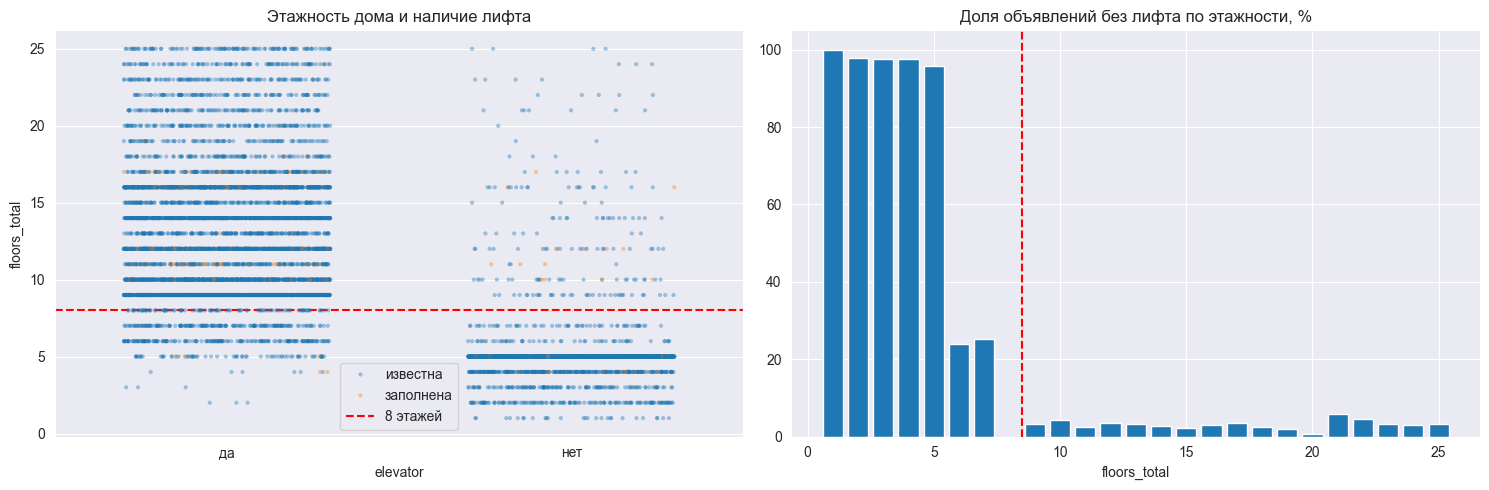

,строк
без лифта и floors_total > 5,296
без лифта и floors_total > 6,241
без лифта и floors_total > 8,184
без лифта и floors_total > 12,86


Подозрительных строк: 184 | среди них с заполненной этажностью: 14


,count,median,max
house_type,,,
блочный,9,12.0,14.0
кирпичный,40,10.0,24.0
монолитный,48,17.0,25.0
панельный,87,12.0,25.0


,floors_total,floor,elevator,house_type,year_built,rent
8114,25.0,8.0,нет,монолитный,2025.0,35000.0
6785,25.0,20.0,нет,монолитный,2021.0,26500.0
5620,25.0,6.0,нет,панельный,2022.0,40500.0
8279,25.0,10.0,нет,монолитный,2012.0,37000.0
5514,24.0,14.0,нет,панельный,2012.0,33500.0
2007,24.0,13.0,нет,монолитный,2023.0,43000.0
12219,24.0,19.0,нет,кирпичный,2024.0,44000.0
4467,23.0,20.0,нет,монолитный,2017.0,23000.0
8923,23.0,6.0,нет,монолитный,2016.0,26500.0
5571,23.0,20.0,нет,монолитный,2020.0,24000.0


Высоких домов без лифта: 170 из них на 1 или 2 этаже: 34 (20.0%)
Флаг high_floor_no_lift_flag: 187 строк (2.20% от выборки)
Из них с заполненной этажностью (floors_total_missing=1): 8
Из них с заполненным лифтом (elevator_missing=1, если есть): нет такого флага

Распределение floor среди flagged:


,count
floor,
3.0,24
4.0,28
5.0,16
6.0,26
7.0,22
8.0,11
9.0,9
10.0,7
11.0,4



Сравнение цены:


,count,median,mean
flag,,,
False,8312,25000.0,40928.0
True,187,28000.0,34152.0


In [68]:
# Лифт и этажность: дома выше FLOORS_LIMIT этажей без лифта нужно проверить
NO_LIFT = "нет"      # как в столбце elevator записано отсутствие лифта
FLOORS_LIMIT = 8     # выше этой этажности без лифта дом считаем подозрительным

check = X_final.assign(rent=y_train, floors_source=X_final["floors_total_missing"].map({0: "известна", 1: "заполнена"}))
print("Значения elevator:", check["elevator"].value_counts(dropna=False).to_dict())
suspicious = (check["elevator"] == NO_LIFT) & (check["floors_total"] > FLOORS_LIMIT)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.stripplot(data=check, x="elevator", y="floors_total", hue="floors_source", jitter=0.3, size=3, alpha=0.4, ax=axes[0])
axes[0].axhline(FLOORS_LIMIT, color="red", linestyle="--", label=f"{FLOORS_LIMIT} этажей")
axes[0].set_title("Этажность дома и наличие лифта")
axes[0].legend()
share_no_lift = (check["elevator"] == NO_LIFT).groupby(check["floors_total"]).mean() * 100
axes[1].bar(share_no_lift.index, share_no_lift.values)
axes[1].axvline(FLOORS_LIMIT + 0.5, color="red", linestyle="--")
axes[1].set_title("Доля объявлений без лифта по этажности, %")
axes[1].set_xlabel("floors_total")
plt.tight_layout()
plt.show()

# Сколько точек попало бы в подозрительные при разных порогах
display(pd.Series({f"без лифта и floors_total > {lim}": int(((check["elevator"] == NO_LIFT) & (check["floors_total"] > lim)).sum()) for lim in (5, 6, FLOORS_LIMIT, 12)}).to_frame("строк"))

# Кто эти подозрительные строки
print("Подозрительных строк:", int(suspicious.sum()), "| среди них с заполненной этажностью:", int(check.loc[suspicious, "floors_total_missing"].sum()))
display(check.loc[suspicious].groupby("house_type")["floors_total"].agg(["count", "median", "max"]))
display(check.loc[suspicious, ["floors_total", "floor", "elevator", "house_type", "year_built", "rent"]].sort_values("floors_total", ascending=False).head(10))

# Сколько из них на 1 или 2 этаже
mask_high_no_elev = (X_clean["elevator"] == "нет") & (X_clean["floors_total"] > 8)
mask_low_floor = X_clean.loc[mask_high_no_elev, "floor"].isin([1, 2])
print(f"Высоких домов без лифта: {mask_high_no_elev.sum()} из них на 1 или 2 этаже: {mask_low_floor.sum()} ({mask_low_floor.mean()*100:.1f}%)")

# Флаг: этажность > 6, нет лифта, и квартира НЕ на 1-2 этаже
mask_flag = (
    (X_final["floors_total"] > 6)
    & (X_final["elevator"] == "нет")
    & (~X_final["floor"].isin([1, 2]))
)
X_final["high_floor_no_lift_flag"] = mask_flag.astype(int)

print(f"Флаг high_floor_no_lift_flag: {mask_flag.sum()} строк ({mask_flag.mean()*100:.2f}% от выборки)")
print(f"Из них с заполненной искусственно этажностью: {X_final.loc[mask_flag, 'floors_total_missing'].sum()}")

# Медианная цена внутри флага vs остальная выборка
price_cmp = check.assign(flag=mask_flag).groupby("flag")["rent"].agg(["count", "median", "mean"]).round(0)
print("\nСравнение цены:")
display(price_cmp)

Вывод: отсутствия лифта в высоких достаточно современных домах сильно смущает, но 20% из них являются квартирами на 1 и 2 этаже, то есть в этом случае лифт не указали специально(*бывают лифты со 2 этажа), также эти точки не выбиваются по другим признакам, поэтому оставим как есть.

## 4.9 Итог по пропускам
### 4.9.1 Сколько пропусков осталось
Финальная проверка итоговой таблицы X_final и X_valid_final.
Вывод: после заполнения категорий пропусков не осталось ни в train, ни в validation. В X_train было 3794 пропуска, очистка добавила ещё 603 (стало 4397), все они закрыты.


In [83]:
# Объединяем train и valid в одну таблицу
missing = pd.DataFrame({
    "train": X_final.isna().sum(),
    "valid": X_valid_final.isna().sum(),
})
missing["train, %"] = (missing["train"] / len(X_final) * 100).round(2)
missing["valid, %"] = (missing["valid"] / len(X_valid_final) * 100).round(2)

# Оставляем только столбцы с пропусками, сортируем по убыванию
missing = missing[(missing["train"] > 0) | (missing["valid"] > 0)]
missing = missing.sort_values("train", ascending=False)

if missing.empty:
    print("Пропусков не осталось ни в train, ни в valid")
else:
    display(missing.rename(columns={
        "train": "пропусков train",
        "valid": "пропусков valid",
        "train, %": "% train",
        "valid, %": "% valid",
    }))

Пропусков не осталось ни в train, ни в valid


### 4.9.2 Журнал заполнения
Записываем в журнал, что и чем заполнено.

## 4.10 Выбросы и странные точки
### 4.10.1 Выбросы по IQR

,известно,min,медиана,max,% выбросов,крайних (3·IQR),асимметрия
rooms,8499,0.0,2.00,5.00,5.93,0,0.42
rent_rub,8499,8000.0,25000.00,1493000.00,5.86,212,9.93
floor,8468,1.0,5.00,25.00,4.06,19,1.24
ceiling_height,8059,2.4,2.67,3.88,3.80,5,1.34
living_area,7809,10.7,26.50,107.50,3.29,28,1.47
total_area,8499,15.7,47.30,171.60,2.99,31,1.32
kitchen_area,7730,4.0,8.50,23.70,2.11,3,0.98
photos_count,8344,0.0,8.00,28.00,0.54,0,0.53
year_built,7690,1920.0,1985.00,2025.00,0.00,0,-0.31
metro_distance_m,8499,80.0,1310.00,9000.00,0.00,0,1.05


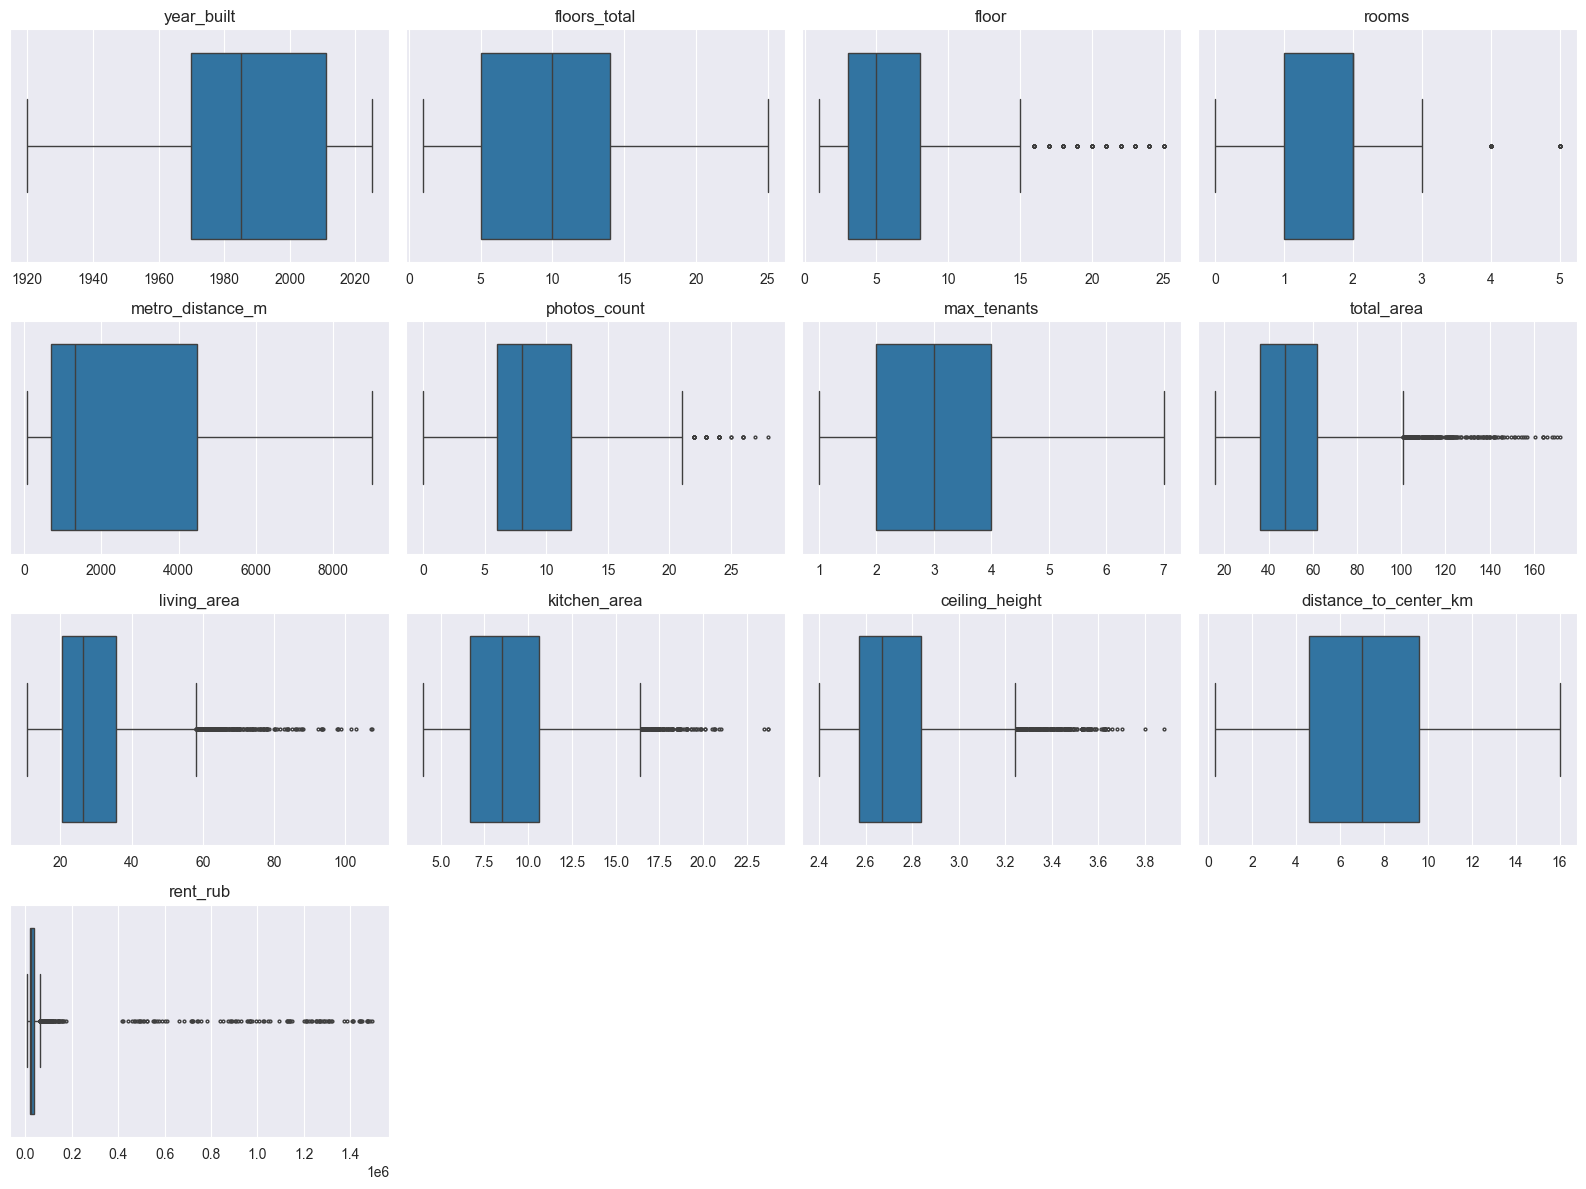

In [81]:
# Выбросы: числа (IQR на исходной шкале и на log1p) и редкие категории
num_all = X_clean[NUM_FEATURES].astype(float).assign(**{TARGET: y_train.astype(float)})

def iqr_flags(data, k):
    """Границы Q1 − k·IQR и Q3 + k·IQR; при IQR = 0 (дискретные признаки) границы не считаем."""
    q1, q3 = data.quantile(0.25), data.quantile(0.75)
    iqr = (q3 - q1).replace(0, np.nan)
    return q1 - k * iqr, q3 + k * iqr

low, high = iqr_flags(num_all, 1.5)
low3, high3 = iqr_flags(num_all, 3)
known = num_all.notna().sum()

out = pd.DataFrame({
    "известно": known, "min": num_all.min(), "медиана": num_all.median(), "max": num_all.max(),
    "% выбросов": ((num_all < low) | (num_all > high)).sum() / known * 100,
    "крайних (3·IQR)": ((num_all < low3) | (num_all > high3)).sum(),
    "асимметрия": num_all.skew(),
})
display(out.sort_values("% выбросов", ascending=False).round(2))

# Ящики с усами по всем числовым столбцам
fig, axes = plt.subplots(int(np.ceil(len(num_all.columns) / 4)), 4, figsize=(16, 3 * int(np.ceil(len(num_all.columns) / 4))))
for ax, c in zip(axes.ravel(), num_all.columns):
    sns.boxplot(x=num_all[c].dropna(), ax=ax, fliersize=2)
    ax.set_title(c)
    ax.set_xlabel("")
for ax in axes.ravel()[len(num_all.columns):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Вывод: есть помеченные выбросами значения, но они вполне возможны. У цены,площадей, этажа и потолков это правдоподобный правый хвост.


### 4.10.2 Логические проверки
Проверяем правдоподобие по смыслу: метро и центр, потолки и год постройки, год постройки и дата публикации, доли площадей, площадь на комнату, жильцы и комнаты, цена за м².

In [84]:
# Логические проверки: странные точки по распределениям признаков
IMPUTED = [c for c in X_final.columns if c.endswith("_missing") and c != "kitchen_area_original_missing"]
d = X_final.assign(rent=y_train)
d["rent_m2"] = d["rent"] / d["total_area"]
d["living_share"] = d["living_area"] / d["total_area"]
d["kitchen_share"] = d["kitchen_area"] / d["total_area"]
d["area_per_room"] = (d["total_area"] / d["rooms"]).where(d["rooms"] > 0)
pub_year = pd.to_datetime(df_train.loc[d.index, "publication_date"], errors="coerce").dt.year

rules = {
    "этаж выше этажности": d["floor"] > d["floors_total"],
    "метро дальше 3 км, центр ближе 3 км": (d["metro_distance_m"] > 3000) & (d["distance_to_center_km"] < 3),
    "потолки ≥ 3.3 м в доме после 1970": (d["ceiling_height"] >= 3.3) & (d["year_built"] >= 1970),
    "жилая доля < 0.25 или > 0.9": (d["living_share"] < 0.25) | (d["living_share"] > 0.9),
    "кухня больше 40% площади": d["kitchen_share"] > 0.4,
    "студия больше 60 м²": (d["rooms"] == 0) & (d["total_area"] > 60),
    "больше 60 м² на комнату": d["area_per_room"] > 60,
    "жильцов меньше комнат": d["max_tenants"] < d["rooms"],
    "жильцов больше комнат + 3": d["max_tenants"] > d["rooms"] + 3,
    "аренда за м² в крайних 0.5%": (d["rent_m2"] < d["rent_m2"].quantile(0.005)) | (d["rent_m2"] > d["rent_m2"].quantile(0.995)),
    "аренда больше 10 медиан": d["rent"] > 10 * d["rent"].median(),
}
imputed_any = d[IMPUTED].eq(1).any(axis=1)
rules_table = pd.DataFrame({
    "строк": {k: int(v.sum()) for k, v in rules.items()},
    "% от train": {k: v.mean() * 100 for k, v in rules.items()},
    "% с заполненными значениями": {k: imputed_any[v].mean() * 100 if v.any() else np.nan for k, v in rules.items()},
})
print("Для сравнения: доля строк с заполненными значениями во всём train:", round(imputed_any.mean() * 100, 1), "%")
display(rules_table.sort_values("строк", ascending=False).round(2))

# Самые дорогие объявления: что у них общего
display(d.nlargest(10, "rent")[["rent", "total_area", "rooms", "district", "house_type", "year_built"]])

Для сравнения: доля строк с заполненными значениями во всём train: 26.0 %


,строк,% от train,% с заполненными значениями
аренда больше 10 медиан,102,1.20,29.41
кухня больше 40% площади,87,1.02,24.14
аренда за м² в крайних 0.5%,86,1.01,24.42
"метро дальше 3 км, центр ближе 3 км",42,0.49,40.48
больше 60 м² на комнату,4,0.05,25.00
потолки ≥ 3.3 м в доме после 1970,2,0.02,100.00
этаж выше этажности,0,0.00,NaN
студия больше 60 м²,0,0.00,NaN
жилая доля < 0.25 или > 0.9,0,0.00,NaN
жильцов больше комнат + 3,0,0.00,NaN


,rent,total_area,rooms,district,house_type,year_built
12128,1493000.0,45.6,2.0,лесной,панельный,1971.8
3292,1483000.0,39.3,1.0,первомайский,панельный,2020.0
3691,1478000.0,39.0,1.0,южный,панельный,1981.0
5851,1476000.0,77.9,3.0,северный,монолитный,2021.0
7596,1472000.0,62.8,2.0,северный,панельный,1982.0
3935,1471000.0,30.1,1.0,первомайский,кирпичный,1985.0
3251,1451000.0,50.5,2.0,лесной,панельный,1987.0
1549,1446000.0,46.1,2.0,промышленный,блочный,1979.0
11501,1442000.0,58.4,2.0,советский,блочный,1990.0
6384,1441000.0,36.0,1.0,северный,монолитный,2012.0


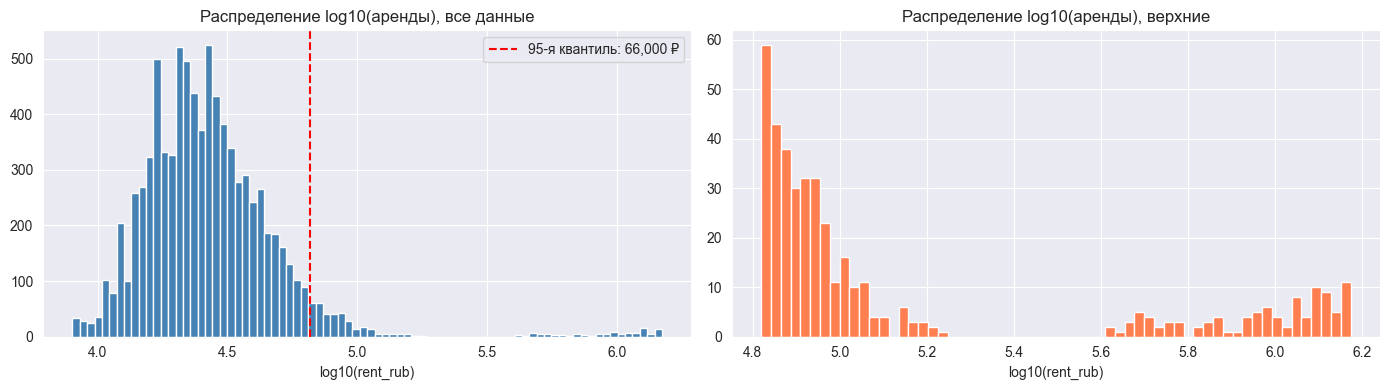

,total_area,living_area,rooms,max_tenants,distance_to_center_km,ceiling_height,kitchen_area,metro_distance_m,photos_count,year_built,...,kitchen_area_original_missing,living_area_missing,kitchen_area_missing,max_tenants_missing,year_built_missing,ceiling_height_missing,floors_total_missing,photos_count_missing,high_floor_no_lift_flag,rent_rub
12128,45.6,29.5,2.0,2.0,15.5,2.6,5.6,4130.0,11.0,1971.8,...,0,0,0,0,1,0,0,0,0,1493000.0
3292,39.3,24.3,1.0,2.0,9.2,2.9,8.2,540.0,2.0,2020.0,...,0,0,0,0,0,0,0,0,0,1483000.0
3691,39.0,19.0,1.0,1.0,10.5,2.5,7.0,7340.0,6.0,1981.0,...,0,0,0,0,0,0,0,0,0,1478000.0
5851,77.9,46.4,3.0,5.0,12.0,2.9,12.0,5260.0,8.0,2021.0,...,0,0,0,0,0,0,0,0,0,1476000.0
7596,62.8,35.1,2.0,3.0,14.3,2.7,7.5,3970.0,6.0,1982.0,...,0,0,0,1,0,0,0,0,0,1472000.0
3935,30.1,16.0,1.0,1.0,5.6,2.6,7.6,210.0,9.0,1985.0,...,0,0,0,0,0,0,0,0,0,1471000.0
3251,50.5,29.1,2.0,2.0,11.6,2.7,7.3,6440.0,8.0,1987.0,...,0,0,0,0,0,0,0,0,0,1451000.0
1549,46.1,21.6,2.0,4.0,8.6,2.6,9.8,7670.0,8.0,1979.0,...,0,0,0,0,0,0,0,0,0,1446000.0
11501,58.4,34.7,2.0,2.0,4.6,2.6,6.1,1100.0,5.0,1990.0,...,0,0,0,0,0,1,0,0,0,1442000.0
6384,36.0,21.8,1.0,1.0,8.7,2.8,11.6,6880.0,22.0,2012.0,...,0,0,0,0,0,0,0,0,0,1441000.0


In [91]:
# Распределение цены аренды (логарифмическая шкала)
rent = y_train.astype(float)
q75 = rent.quantile(0.95)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Левый график: всё распределение
axes[0].hist(np.log10(rent), bins=80, color="steelblue", edgecolor="white")
axes[0].axvline(np.log10(q75), color="red", linestyle="--", label=f"95-я квантиль: {q75:,.0f} ₽")
axes[0].set_title("Распределение log10(аренды), все данные")
axes[0].set_xlabel("log10(rent_rub)")
axes[0].legend()

# Правый график: только верхние 25%
top = rent[rent >= q75]
axes[1].hist(np.log10(top), bins=60, color="coral", edgecolor="white")
axes[1].set_title(f"Распределение log10(аренды), верхние")
axes[1].set_xlabel("log10(rent_rub)")

plt.tight_layout()
plt.show()

# Топ-10 самых дорогих квартир
# Порядок столбцов: сначала самые важные для цены (по |Spearman|), потом остальные
priority_num = ["total_area", "living_area", "rooms", "max_tenants", "distance_to_center_km",
                "ceiling_height", "kitchen_area", "metro_distance_m", "photos_count",
                "year_built", "floors_total", "floor"]
priority_cat = ["district", "house_type", "renovation", "elevator", "furniture",
                "balcony", "parking", "appliances", "pets_allowed", "seller_type"]
other_cols = [c for c in X_final.columns if c not in priority_num + priority_cat]
ordered_cols = priority_num + priority_cat + other_cols

top10_idx = rent.nlargest(10).index
top10 = pd.concat([X_final.loc[top10_idx, ordered_cols],
                   rent.loc[top10_idx].to_frame("rent_rub")], axis=1)
display(top10.round(1))